<h1 style="font-weight:900; color:#0E2841; color:var(--vscode-foreground, #0E2841); margin:0.4em 0 0.2em; overflow:hidden;"><span style="float:right"><span class="modulchip" style="font-size:0.55em; font-weight:bold; letter-spacing:0.02em; border:1.5px solid #1F5FB0; color:#1F5FB0; padding:1px 8px; border-radius:10px; margin-left:12px; vertical-align:0.35em; white-space:nowrap;">M3 · Tensoren und Autograd</span></span>Lerneinheit 6 · PyTorch: Tensoren, Device, Messen und der Trainings-Loop</h1>

<div style="font-size:0.8em; color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); margin-top:-4px;">Version 1.0</div>

<span style="color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); font-size:0.9em;">Tensor to GPU – Programmierkonzepte für KI · Prof. Dr. Stephan Kurpjuweit · Hochschule Worms · © 2026</span>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Lernziele</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Nach dieser Lerneinheit können Sie …</p>
<ul style="list-style:none; padding-left:0.2em; margin:6px 0 0;">
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>Form, Datentyp und Device eines Tensors ablesen und festlegen und NumPy-Ausdrücke aus LE03 in PyTorch übertragen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>für die eingeführten Fälle (<code style="color:inherit;">view</code>, <code style="color:inherit;">reshape</code>, Transponieren, Slicing, <code style="color:inherit;">from_numpy</code>) vorhersagen, ob eine Sicht oder eine Kopie entsteht,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>den Operator <code style="color:inherit;">row_l2_normalize</code> in PyTorch schreiben und gegen die NumPy-Fassung und den Vertrag testen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>Tensoren und Modelle zwischen CPU und GPU bewegen und den Fehler bei gemischten Devices erkennen und beheben,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>erklären, warum eine Zeitmessung auf der GPU ohne Synchronisation zu kurz ausfallen kann, und eine Laufzeit mit Aufwärmen, Synchronisation und Median messen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>ein Modell aus <code style="color:inherit;">nn.Linear</code>-Schichten anlegen, seine Parameter mit Form und Anzahl angeben und Logit, Wahrscheinlichkeit und Loss unterscheiden,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>einen Trainings-Loop aus den fünf Schritten schreiben und angeben, was <code style="color:inherit;">backward()</code>, <code style="color:inherit;">step()</code> und <code style="color:inherit;">zero_grad()</code> jeweils verändern,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>den Verlauf des Loss darstellen und das Modell auf dem Testteil bewerten,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>erklären, wie <code style="color:inherit;">nn.Module</code> seine Parameter findet, und was daraus für <code style="color:inherit;">parameters()</code>, <code style="color:inherit;">state_dict()</code> und <code style="color:inherit;">.to(device)</code> folgt.</li>
</ul>

</div>
</div>

**Was ist PyTorch, und wofür braucht man es?** PyTorch ist eine frei verfügbare Python-Bibliothek für das Rechnen mit Tensoren und für das Bauen und Trainieren neuronaler Netze. Sie wurde bei Facebook (heute Meta) entwickelt und wird seit 2022 von der PyTorch Foundation unter dem Dach der Linux Foundation getragen. In der Forschung und in vielen Produkten ist sie ein Standardwerkzeug für maschinelles Lernen. PyTorch leistet vier Dinge:

| Wofür | Was PyTorch dafür mitbringt | Wo im Kurs |
|---|---|---|
| mit Tensoren rechnen | den Typ `torch.Tensor` mit Operationen, wie Sie sie von NumPy-Arrays kennen | Kapitel <a href="#kap-der-tensor-als-rechenobjekt">6.1</a> und <a href="#kap-der-semester-operator-in-pytorch">6.2</a> |
| auf der GPU rechnen | das Device: Derselbe Code rechnet auf dem Prozessor oder auf der GPU. Große Tensor-Rechnungen laufen auf der GPU oft um ein Vielfaches schneller | Kapitel <a href="#kap-device-cpu-und-gpu">6.3</a> und <a href="#kap-richtig-messen">6.4</a> |
| Gradienten automatisch berechnen | Autograd: PyTorch zeichnet den Rechenweg auf und berechnet daraus, wie jeder Parameterwert eines Modells den Loss beeinflusst. Darauf beruht das Training | Kapitel <a href="#kap-der-trainings-loop">6.6</a>, im Detail in der nächsten Lerneinheit |
| Modelle bauen und trainieren | `torch.nn` mit Schichten und Loss-Funktionen, `torch.optim` mit Optimierern, `torch.utils.data` mit `Dataset` und `DataLoader` | Kapitel <a href="#kap-das-erste-modell">6.5</a> bis <a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet">6.7</a>, der `DataLoader` in LE05 |

NumPy rechnet mit Arrays auf dem Prozessor. PyTorch ergänzt die automatische Berechnung von Gradienten, fertige Bausteine für Modelle und Training und die Ausführung auf GPUs. Trainieren kann man auch auf der CPU. Ob eine GPU die Rechnung beschleunigt, hängt unter anderem von der Größe der Rechnung und vom Aufwand für die Übertragung der Daten ab. Das untersuchen wir in Kapitel <a href="#kap-richtig-messen">6.4</a>.

**Worum es in dieser Lerneinheit geht.** In LE05 haben wir die Titanic-Tabelle bis zum `DataLoader` gebracht: Tensoren, die in Batches von 64 Beispielen ausgegeben werden. Dort war der Tensor ein Behälter für Daten. In dieser Lerneinheit rechnen wir mit ihm und trainieren damit ein Modell. Drei Fragen führen durch die Kapitel:

1. **Womit rechnen wir?** Mit Tensoren, die sich fast wie die Arrays aus LE03 verhalten. Kapitel <a href="#kap-der-tensor-als-rechenobjekt">6.1</a> überträgt, was Sie von NumPy kennen, und Kapitel <a href="#kap-der-semester-operator-in-pytorch">6.2</a> schreibt den Operator `row_l2_normalize` in PyTorch.
2. **Wo rechnen wir?** Auf der CPU oder auf der GPU. Kapitel <a href="#kap-device-cpu-und-gpu">6.3</a> zeigt, wie ein Tensor auf die GPU kommt, und Kapitel <a href="#kap-richtig-messen">6.4</a>, wie man Laufzeiten auf der GPU korrekt misst.
3. **Wie wird daraus Lernen?** Kapitel <a href="#kap-das-erste-modell">6.5</a> baut die Rechnung der logistischen Regression aus LE05 als PyTorch-Modell. Kapitel <a href="#kap-der-trainings-loop">6.6</a> trainiert es in fünf sichtbaren Schritten und bewertet es auf dem Testteil. Kapitel <a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet">6.7</a> tauscht das Modell gegen ein kleines neuronales Netz aus.

Dieses Modul erklärt, wie die Rechnung ausgeführt wird. Warum ein Netz so aufgebaut ist und wie man gute Einstellungen für das Training findet, ist Stoff der Module zu neuronalen Netzen. Das Netz, der Loss (die Zahl, die misst, wie weit die Vorhersagen vom Ziel entfernt sind) und der Optimierer (das Verfahren, das die Parameter verändert) sind deshalb vorgegeben. Wie `loss.backward()` die Gradienten berechnet, behandeln wir in der nächsten Lerneinheit. Hier beobachten wir, was hineingeht und was herauskommt.

Im Termin gehen wir mindestens bis zur Bewertung des ersten Modells auf dem Testteil, also bis zum Ende von Kapitel <a href="#kap-der-trainings-loop">6.6</a>. Was im Termin offen bleibt, arbeiten Sie mit Skript und Notebook nach. Das gilt auch für Kapitel <a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet">6.7</a>, falls die Zeit dafür nicht reicht. Die Zellen laufen mit und ohne GPU. Wo eine Ausgabe von der GPU abhängt, zeigt das Skript die Werte von Colab mit einer GPU vom Typ T4.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Inhalt</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul style="margin:0; padding-left:1.2em;"><li style="margin:5px 0;">6.1&nbsp;&nbsp;<a href="#kap-der-tensor-als-rechenobjekt" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Der Tensor als Rechenobjekt</a></li><li style="margin:5px 0;">6.2&nbsp;&nbsp;<a href="#kap-der-semester-operator-in-pytorch" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Der Semester-Operator in PyTorch</a></li><li style="margin:5px 0;">6.3&nbsp;&nbsp;<a href="#kap-device-cpu-und-gpu" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Device: CPU und GPU</a></li><li style="margin:5px 0;">6.4&nbsp;&nbsp;<a href="#kap-richtig-messen" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Richtig messen</a></li><li style="margin:5px 0;">6.5&nbsp;&nbsp;<a href="#kap-das-erste-modell" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Das erste Modell</a></li><li style="margin:5px 0;">6.6&nbsp;&nbsp;<a href="#kap-der-trainings-loop" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Der Trainings-Loop</a></li><li style="margin:5px 0;">6.7&nbsp;&nbsp;<a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Ein zweites Modell und wie nn.Module seine Parameter findet</a></li></ul>

</div>
</div>

<div style="border:2px solid #156082; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#156082; font-weight:bold; font-size:1.08em;">Vor dem Start: GPU einschalten</span></div>
<p>Die Zellen dieser Lerneinheit laufen auch ohne GPU. Die Kapitel zu Device und Messen sind aber nur mit GPU vollständig.</p>
<ul>
<li><strong>Colab:</strong> Menü „Laufzeit“, „Laufzeittyp ändern“, als Hardwarebeschleuniger „T4 GPU“ wählen und speichern. Die Laufzeit startet dabei neu. Führen Sie die Zellen danach von oben aus.</li>
<li><strong>JupyterHub der Hochschule:</strong> Die GPU ist eingerichtet. Mehrere Personen teilen sich eine GPU, Ihre Messwerte streuen deshalb stärker als in Colab.</li>
</ul>
<p>Ob PyTorch eine GPU sieht, zeigt die Ladezelle im ersten Kapitel.</p>

</div>

## <a id="kap-der-tensor-als-rechenobjekt"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.1&nbsp;&nbsp;Der Tensor als Rechenobjekt</span>

Die Ladezelle stellt die zwei Dateien dieser Lerneinheit bereit: die bereinigte Titanic-Tabelle aus LE04 und die Embeddings der 400 Absätze, die Sie seit der ersten Lerneinheit kennen. Die zweite Zelle importiert die Bibliotheken und zeigt, ob PyTorch eine GPU sieht. Führen Sie beide einfach aus.

In [ ]:
# Kursdaten bereitstellen — nutzt data/, lädt Fehlendes aus dem Kursrepo nach
from pathlib import Path
from urllib.request import urlretrieve
for _name in ["titanic_clean.csv", "appetizer_embeddings.npy"]:
    _ziel = Path("data") / _name
    if not _ziel.exists():
        _ziel.parent.mkdir(parents=True, exist_ok=True)
        try:
            urlretrieve("https://raw.githubusercontent.com/skuhswo/tensor-to-gpu-material/main/data/" + _name, _ziel)
        except Exception as _fehler:
            _ziel.unlink(missing_ok=True)          # keine halbe Datei zurücklassen
            _tipp = ""
            if "CERTIFICATE" in str(_fehler):      # Python von python.org auf dem Mac
                _tipp = (" Auf dem Mac zuerst 'Install Certificates.command' im Ordner "
                         "Programme/Python ausführen.")
            if _name.endswith(".md"):               # Datenblatt: Lektüre, kein Pflichtteil
                print(_ziel, "nicht nachgeladen (Datenblatt, nur Lektüre):", type(_fehler).__name__)
                continue
            raise RuntimeError(f"{_ziel} fehlt und ließ sich nicht nachladen ({type(_fehler).__name__}). "
                               "Legen Sie den Ordner data/ aus dem ZIP der Lerneinheit neben dieses Notebook."
                               + _tipp) from None
    print(_ziel, "\u2713")

In [ ]:
# Vorgabe: Bibliotheken — einfach ausführen
import math
import statistics
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

print("PyTorch", torch.__version__, "| GPU verfügbar:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: Bibliotheken — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">math</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">statistics</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">time</span>

<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">numpy</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">np</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">pandas</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">pd</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">matplotlib.pyplot</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">plt</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">torch</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">torch.nn</code> enthält die Bausteine für Modelle. Der Kurzname <code style="color:inherit;">nn</code> ist Konvention, so wie <code style="color:inherit;">np</code> für NumPy</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">torch</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> nn
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">torch.utils.data</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> Dataset, DataLoader

<span style="color: #008000">print</span>(<span style="color: #BA2121">"PyTorch"</span>, torch<span style="color: #666">.</span>__version__, <span style="color: #BA2121">"| GPU verfügbar:"</span>, torch<span style="color: #666">.</span>cuda<span style="color: #666">.</span>is_available())
<span style="color: #008000; font-weight: bold">if</span> torch<span style="color: #666">.</span>cuda<span style="color: #666">.</span>is_available():
    <span style="color: #008000">print</span>(<span style="color: #BA2121">"GPU:"</span>, torch<span style="color: #666">.</span>cuda<span style="color: #666">.</span>get_device_name(<span style="color: #666">0</span>))</code></pre></details>

**Drei Begriffe vorab.** Ein Tensor ist wie ein NumPy-Array ein Block gleichartiger Zahlen mit einer Form. Aus dem Überblick am Anfang brauchen wir drei Begriffe gleich genauer:

1. **Das Device.** Ein Tensor kann im Hauptspeicher liegen oder im Speicher einer GPU. Dieselbe Zeile Code rechnet dann auf dem Prozessor oder auf der GPU (Kapitel <a href="#kap-device-cpu-und-gpu">6.3</a> und <a href="#kap-richtig-messen">6.4</a>).
2. **Die Aufzeichnung des Rechenwegs.** PyTorch kann beim Rechnen mitschreiben, aus welchen Tensoren und mit welchen Operationen ein Ergebnis entstanden ist. Aus dieser Aufzeichnung berechnet PyTorch auf Wunsch Gradienten. Ein Gradient gibt für jeden beteiligten Wert an, wie stark sich das Ergebnis ändert, wenn sich dieser Wert ein wenig ändert. Das Training eines Modells beruht auf diesen Gradienten (Kapitel <a href="#kap-der-trainings-loop">6.6</a>). PyTorch schreibt nur bei Tensoren mit, bei denen das eingeschaltet ist. Bei den Tensoren der ersten vier Kapitel ist es ausgeschaltet.
3. **Bausteine für Modelle.** Ein Modell ist in PyTorch ein Objekt. Es enthält Tensoren, deren Werte das Training anpasst. Diese Tensoren heißen Parameter. Ein Modell lässt sich wie eine Funktion aufrufen: `model(x)` rechnet aus einer Eingabe `x` eine Ausgabe. Das Paket `torch.nn` liefert fertige Modelle und die Bausteine für eigene (Kapitel <a href="#kap-das-erste-modell">6.5</a> bis <a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet">6.7</a>).

Wir beginnen mit einem Tensor, den man vollständig überblickt: zwei Zeilen mit je drei Werten. `torch.tensor` legt ihn aus einer verschachtelten Liste an, so wie `np.array` ein Array anlegt.

In [ ]:
m = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(m)
print(m.shape, m.dtype, m.device)

Zu jedem Tensor gehören drei Angaben. Zwei kennen Sie vom Array, die dritte ist neu:

- **`shape`** ist die Form, hier zwei Zeilen und drei Spalten. PyTorch schreibt sie als `torch.Size([2, 3])`. `torch.Size` ist eine Unterklasse des Python-Tupels. Die Form lässt sich deshalb überall wie das Tupel `(2, 3)` verwenden, zum Beispiel im Vergleich `m.shape == (2, 3)` oder beim Auspacken `rows, cols = m.shape`.
- **`dtype`** ist der Datentyp der Werte. Aus Python-Kommazahlen entsteht `float32`. NumPy hätte an derselben Stelle `float64` gewählt.
- **`device`** ist das Gerät, auf dem die Werte liegen und auf dem mit ihnen gerechnet wird. `cpu` steht für Hauptspeicher und Prozessor. In Kapitel <a href="#kap-device-cpu-und-gpu">6.3</a> bringen Sie einen Tensor auf die GPU.

**Anlegen.** Viele Funktionen zum Anlegen heißen wie in NumPy, etwa `zeros` und `arange`. Zwei Regeln zum Datentyp sollten Sie sich merken: Aus ganzen Python-Zahlen entsteht `int64`, aus Kommazahlen `float32`. `torch.from_numpy` übernimmt dagegen den Datentyp des Arrays, das kennen Sie aus LE05.

In [ ]:
print(torch.zeros(2, 3))
print(torch.arange(6))
print(torch.arange(6).dtype, torch.tensor([1.0, 2.0]).dtype)
print(torch.from_numpy(np.array([1.0, 2.0])).dtype)

**Rechnen.** Tensoren rechnen elementweise, und Broadcasting gilt mit denselben Regeln wie in NumPy (LE03). Zwei Argumente heißen anders als dort: Die Achse heißt in PyTorch `dim` statt `axis`, und der Schalter, der eine Achse der Länge 1 behält, heißt `keepdim` statt `keepdims`. `dim=0` rechnet über die Zeilen hinweg und liefert einen Wert je Spalte, `dim=1` rechnet über die Spalten hinweg und liefert einen Wert je Zeile.

In [ ]:
print("m * 2:", m * 2, sep="\n")
print("m.sum(dim=0):", m.sum(dim=0), sep="\n")
row_sum = m.sum(dim=1, keepdim=True)
print("row_sum:", row_sum, sep="\n")
print("m / row_sum:", m / row_sum, sep="\n")
# Formen: m (2, 3) -> sum(dim=1, keepdim=True) (2, 1) -> m / row_sum (2, 3)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Jede Ausgabe beginnt mit dem Ausdruck, der sie erzeugt. <code style="color:inherit;">sep=&quot;\n&quot;</code> setzt den Tensor in die nächste Zeile</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"m * 2:"</span>, m <span style="color: #666">*</span> <span style="color: #666">2</span>, sep<span style="color: #666">=</span><span style="color: #BA2121">"</span><span style="color: #AA5D1F; font-weight: bold">\n</span><span style="color: #BA2121">"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; Summe über die Zeilen hinweg: ein Wert je Spalte, Form (3,)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"m.sum(dim=0):"</span>, m<span style="color: #666">.</span>sum(dim<span style="color: #666">=0</span>), sep<span style="color: #666">=</span><span style="color: #BA2121">"</span><span style="color: #AA5D1F; font-weight: bold">\n</span><span style="color: #BA2121">"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; Summe je Zeile, die Achse bleibt mit Länge 1 erhalten: Form (2, 1)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">row_sum <span style="color: #666">=</span> m<span style="color: #666">.</span>sum(dim<span style="color: #666">=1</span>, keepdim<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"row_sum:"</span>, row_sum, sep<span style="color: #666">=</span><span style="color: #BA2121">"</span><span style="color: #AA5D1F; font-weight: bold">\n</span><span style="color: #BA2121">"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; Broadcasting: (2, 3) geteilt durch (2, 1) ergibt (2, 3). Jede Zeile wird durch ihre eigene Summe geteilt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"m / row_sum:"</span>, m <span style="color: #666">/</span> row_sum, sep<span style="color: #666">=</span><span style="color: #BA2121">"</span><span style="color: #AA5D1F; font-weight: bold">\n</span><span style="color: #BA2121">"</span>)
<span style="color: #3D7B7B; font-style: italic"># Formen: m (2, 3) -&gt; sum(dim=1, keepdim=True) (2, 1) -&gt; m / row_sum (2, 3)</span></code></pre></details>

Eine Reduktion über alle Werte liefert einen Tensor ohne Achsen, also mit der Form `()`. Er enthält genau eine Zahl. `.item()` holt diese Zahl als gewöhnliche Python-Zahl heraus. Das brauchen wir später, um den Loss in eine Liste zu schreiben.

In [ ]:
total = m.sum()
print(total, total.shape)
print(total.item(), type(total.item()))

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: NumPy und PyTorch nebeneinander</span></div>
<table>
<thead>
<tr>
<th>Absicht</th>
<th>NumPy</th>
<th>PyTorch</th>
</tr>
</thead>
<tbody>
<tr>
<td>aus einer Liste anlegen</td>
<td><code style="color:inherit;">np.array([[1.0, 2.0]])</code></td>
<td><code style="color:inherit;">torch.tensor([[1.0, 2.0]])</code></td>
</tr>
<tr>
<td>Standardtyp für Kommazahlen</td>
<td><code style="color:inherit;">float64</code></td>
<td><code style="color:inherit;">float32</code></td>
</tr>
<tr>
<td>Form und Datentyp ablesen</td>
<td><code style="color:inherit;">a.shape</code>, <code style="color:inherit;">a.dtype</code></td>
<td><code style="color:inherit;">t.shape</code>, <code style="color:inherit;">t.dtype</code>, dazu <code style="color:inherit;">t.device</code></td>
</tr>
<tr>
<td>über eine Achse reduzieren</td>
<td><code style="color:inherit;">a.sum(axis=1)</code></td>
<td><code style="color:inherit;">t.sum(dim=1)</code></td>
</tr>
<tr>
<td>die Achse dabei behalten</td>
<td><code style="color:inherit;">keepdims=True</code></td>
<td><code style="color:inherit;">keepdim=True</code></td>
</tr>
<tr>
<td>Wurzel, elementweise</td>
<td><code style="color:inherit;">np.sqrt(a)</code></td>
<td><code style="color:inherit;">torch.sqrt(t)</code></td>
</tr>
<tr>
<td>Position des größten Werts je Zeile</td>
<td><code style="color:inherit;">a.argmax(axis=1)</code></td>
<td><code style="color:inherit;">t.argmax(dim=1)</code></td>
</tr>
<tr>
<td>Zeilen über eine Maske auswählen</td>
<td><code style="color:inherit;">a[mask]</code></td>
<td><code style="color:inherit;">t[mask]</code></td>
</tr>
<tr>
<td>Werte näherungsweise vergleichen</td>
<td><code style="color:inherit;">np.allclose(a, b)</code></td>
<td><code style="color:inherit;">torch.allclose(t, u)</code></td>
</tr>
<tr>
<td>eine einzelne Zahl herausholen</td>
<td><code style="color:inherit;">a.item()</code></td>
<td><code style="color:inherit;">t.item()</code></td>
</tr>
<tr>
<td>Array und Tensor ineinander überführen</td>
<td><code style="color:inherit;">t.numpy()</code></td>
<td><code style="color:inherit;">torch.from_numpy(a)</code></td>
</tr>
</tbody>
</table>
<p>PyTorch nimmt an vielen Stellen auch <code style="color:inherit;">axis</code> an. Im Kurs und in der Dokumentation von PyTorch steht <code style="color:inherit;">dim</code>, deshalb verwenden wir <code style="color:inherit;">dim</code>.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 6.1 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Notieren Sie sich für jede der fünf Zeilen Ihre Vorhersage (Form, Datentyp oder Werte), bevor Sie die Zelle ausführen. Vergleichen Sie danach.</p>

</div>
</div>

In [ ]:
print(m.sum(dim=0).shape)
print(m.mean(dim=1, keepdim=True).shape)
print((m - m.mean(dim=0)).shape)
print((torch.arange(3) / 2).dtype)
print(m.max().item())

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">8 min</span>✏️ Aufgabe 6.1 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Übertragen Sie sechs NumPy-Zeilen nach PyTorch. Die nächste Zelle legt ein Array <code style="color:inherit;">a</code> und denselben Inhalt als Tensor <code style="color:inherit;">t</code> an und rechnet die sechs Ergebnisse mit NumPy aus. Ersetzen Sie in der Aufgabenzelle jedes <code style="color:inherit;">...</code> durch die PyTorch-Fassung, die mit <code style="color:inherit;">t</code> rechnet.</p>
<p>Wer früher fertig ist: Was passiert bei <code style="color:inherit;">torch.arange(6).mean()</code>? Probieren Sie es in einer neuen Zelle aus und lesen Sie die Fehlermeldung.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> In fünf der sechs Zeilen genügt es, <code style="color:inherit;">axis</code> durch <code style="color:inherit;">dim</code>, <code style="color:inherit;">keepdims</code> durch <code style="color:inherit;">keepdim</code> und <code style="color:inherit;">np.</code> durch <code style="color:inherit;">torch.</code> zu ersetzen. In der Zeile mit der Maske ändert sich nichts außer dem Namen des Tensors.</p></div></details>
</div>
</div>

In [ ]:
a = np.array([[3.0, 4.0, 0.0],
              [1.0, 2.0, 2.0],
              [6.0, 0.0, 8.0],
              [0.0, 5.0, 12.0]], dtype=np.float32)

col_mean_np = a.mean(axis=0)                       # 1. Mittelwert je Spalte
row_sum_np = a.sum(axis=1, keepdims=True)          # 2. Summe je Zeile, Form (4, 1)
shares_np = a / a.sum(axis=1, keepdims=True)       # 3. Anteil jedes Werts an seiner Zeilensumme
biggest_np = a.argmax(axis=1)                      # 4. Spalte des größten Werts je Zeile
selected_np = a[a[:, 0] > 2].mean()                # 5. Mittelwert aller Werte in den Zeilen, deren erster Wert größer als 2 ist
length_np = np.sqrt((a * a).sum(axis=1))           # 6. Länge jeder Zeile
print(col_mean_np, biggest_np, selected_np, length_np)

In [ ]:
t = torch.from_numpy(a.copy())                    # derselbe Inhalt als Tensor, eigener Speicher

col_mean = ...   # 1. Mittelwert je Spalte
row_sum = ...    # 2. Summe je Zeile, Form (4, 1)
shares = ...     # 3. Anteil jedes Werts an seiner Zeilensumme
biggest = ...    # 4. Spalte des größten Werts je Zeile
selected = ...   # 5. Mittelwert aller Werte in den Zeilen, deren erster Wert größer als 2 ist
length = ...     # 6. Länge jeder Zeile

In [ ]:
# Prüfzelle — einfach ausführen
pairs = [("col_mean", col_mean, col_mean_np), ("row_sum", row_sum, row_sum_np), ("shares", shares, shares_np),
         ("biggest", biggest, biggest_np), ("selected", selected, selected_np), ("length", length, length_np)]
for name, got, expected in pairs:
    assert isinstance(got, torch.Tensor), f"{name} soll ein Tensor sein, ist {type(got).__name__}"
    assert tuple(got.shape) == expected.shape, f"{name}: Form {tuple(got.shape)} statt {expected.shape}"
    assert np.allclose(got.numpy(), expected, atol=1e-6), f"{name}: die Werte weichen von der NumPy-Fassung ab"
assert row_sum.shape == (4, 1), "row_sum soll die Achse behalten (keepdim=True)"
print("Alle sechs Ergebnisse stimmen mit NumPy überein.")

**Sicht oder Kopie.** In LE03 haben Sie gesehen, dass manche Operationen kein neues Array anlegen, sondern eine Sicht auf denselben Speicher liefern. Bei Tensoren ist es genauso, und die Frage ist dieselbe: Wirkt eine Änderung am Ergebnis auf das Original zurück? Wir behandeln hier vier Fälle. Weitere stehen in der [PyTorch-Dokumentation zu Sichten](https://pytorch.org/docs/stable/tensor_view.html).

`view` zeigt denselben Speicher in einer anderen Form. Das Ergebnis ist immer eine Sicht. Passt die gewünschte Form nicht zur Lage der Werte im Speicher, bricht `view` mit einer Fehlermeldung ab. `reshape` versucht dasselbe und legt eine Kopie an, wenn eine Sicht nicht möglich ist.

In [ ]:
v = m.view(3, 2)                 # dieselben sechs Werte, als drei Zeilen mit zwei Spalten
v[0, 0] = 99.0
print(m)
m[0, 0] = 1.0                    # Original wiederherstellen
# Formen: m (2, 3) -> view(3, 2) (3, 2), derselbe Speicher

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">v <span style="color: #666">=</span> m<span style="color: #666">.</span>view(<span style="color: #666">3</span>, <span style="color: #666">2</span>)                 <span style="color: #3D7B7B; font-style: italic"># dieselben sechs Werte, als drei Zeilen mit zwei Spalten</span>
v[<span style="color: #666">0</span>, <span style="color: #666">0</span>] <span style="color: #666">=</span> <span style="color: #666">99.0</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Die Änderung an <code style="color:inherit;">v</code> ist in <code style="color:inherit;">m</code> sichtbar: <code style="color:inherit;">v</code> ist eine Sicht</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(m)
m[<span style="color: #666">0</span>, <span style="color: #666">0</span>] <span style="color: #666">=</span> <span style="color: #666">1.0</span>                    <span style="color: #3D7B7B; font-style: italic"># Original wiederherstellen</span>
<span style="color: #3D7B7B; font-style: italic"># Formen: m (2, 3) -&gt; view(3, 2) (3, 2), derselbe Speicher</span></code></pre></details>

Auch Transponieren (`m.T`) und Slicing liefern Sichten. NumPy verhält sich hier genauso, die folgenden Begriffe gelten also für Arrays und Tensoren gleichermaßen. Beim Transponieren ändert sich nur die Lesart: Derselbe Speicher wird spaltenweise statt zeilenweise durchlaufen. Die Werte liegen dann nicht mehr in der Reihenfolge im Speicher, in der der Tensor sie ausgibt. Ein Tensor heißt zusammenhängend (englisch contiguous), wenn seine Werte in Lesereihenfolge hintereinander im Speicher stehen. `is_contiguous()` prüft, ob das der Fall ist.

In [ ]:
mt = m.T
print(mt.shape, m.is_contiguous(), mt.is_contiguous())
try:
    mt.view(6)
except RuntimeError as err:
    print("RuntimeError:", str(err)[:60], "...")
print(mt.reshape(6))
print(mt.contiguous().is_contiguous())

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">mt <span style="color: #666">=</span> m<span style="color: #666">.</span>T
<span style="color: #008000">print</span>(mt<span style="color: #666">.</span>shape, m<span style="color: #666">.</span>is_contiguous(), mt<span style="color: #666">.</span>is_contiguous())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">view</code> kann aus diesem Tensor keine Zeile mit sechs Werten machen und bricht ab</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">try</span>:
    mt<span style="color: #666">.</span>view(<span style="color: #666">6</span>)
<span style="color: #008000; font-weight: bold">except</span> <span style="color: #CB3F38; font-weight: bold">RuntimeError</span> <span style="color: #008000; font-weight: bold">as</span> err:
    <span style="color: #008000">print</span>(<span style="color: #BA2121">"RuntimeError:"</span>, <span style="color: #008000">str</span>(err)[:<span style="color: #666">60</span>], <span style="color: #BA2121">"..."</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">reshape</code> legt hier eine Kopie an. <code style="color:inherit;">contiguous()</code> legt die Werte in Lesereihenfolge neu ab</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(mt<span style="color: #666">.</span>reshape(<span style="color: #666">6</span>))
<span style="color: #008000">print</span>(mt<span style="color: #666">.</span>contiguous()<span style="color: #666">.</span>is_contiguous())</code></pre></details>

`contiguous()` kopiert nur, wenn es nötig ist. Bei einem Tensor, der schon zusammenhängend ist, gibt die Methode ihn selbst zurück. In NumPy leistet `np.ascontiguousarray(a)` dasselbe. Die meisten Rechnungen in PyTorch funktionieren auch mit Tensoren, die nicht zusammenhängend sind. Wir brauchen den Begriff im nächsten Kapitel, weil der Vertrag unseres Operators solche Eingaben abweist.

Der vierte Fall ist der Übergang zu NumPy. `torch.from_numpy(a)` liefert einen Tensor, der sich den Speicher mit dem Array `a` teilt. Umgekehrt teilt sich `t.numpy()` den Speicher mit dem Tensor `t`. Das haben Sie in LE05 gesehen. `torch.tensor(a)` kopiert die Werte dagegen in einen eigenen Speicher.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Sicht oder Kopie bei Tensoren</span></div>
<table>
<thead>
<tr>
<th>Operation</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">t.view(...)</code></td>
<td>Sicht, oder Fehlermeldung, wenn die Form nicht zur Lage im Speicher passt</td>
</tr>
<tr>
<td><code style="color:inherit;">t.reshape(...)</code></td>
<td>Sicht, wenn möglich, sonst Kopie</td>
</tr>
<tr>
<td><code style="color:inherit;">t.T</code>, <code style="color:inherit;">t[1:]</code>, <code style="color:inherit;">t[:, ::2]</code></td>
<td>Sicht</td>
</tr>
<tr>
<td><code style="color:inherit;">t.contiguous()</code></td>
<td>der Tensor selbst, wenn er schon zusammenhängend ist, sonst eine Kopie</td>
</tr>
<tr>
<td><code style="color:inherit;">t.clone()</code></td>
<td>Kopie (das Gegenstück zu <code style="color:inherit;">a.copy()</code>)</td>
</tr>
<tr>
<td><code style="color:inherit;">torch.from_numpy(a)</code>, <code style="color:inherit;">t.numpy()</code></td>
<td>derselbe Speicher wie das Array oder der Tensor, aus dem das Ergebnis entsteht</td>
</tr>
<tr>
<td><code style="color:inherit;">torch.tensor(a)</code></td>
<td>Kopie</td>
</tr>
<tr>
<td>Rechnungen wie <code style="color:inherit;">t * 2</code> oder <code style="color:inherit;">t.sum(dim=0)</code></td>
<td>neuer Tensor</td>
</tr>
</tbody>
</table>

</div>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Gegeben ist der Tensor <code style="color:inherit;">t = torch.tensor([[1.0, 2.0], [3.0, 4.0]])</code>. Jemand holt mit <code style="color:inherit;">first = t[0]</code> die erste Zeile heraus und setzt danach mit <code style="color:inherit;">first[0] = 0.0</code> ihren ersten Wert auf null. Hat sich dadurch auch <code style="color:inherit;">t</code> verändert? Und wie holt man die erste Zeile heraus, wenn <code style="color:inherit;">t</code> unverändert bleiben soll?</p>

</div>

## <a id="kap-der-semester-operator-in-pytorch"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.2&nbsp;&nbsp;Der Semester-Operator in PyTorch</span>

Seit LE03 begleitet uns ein Operator: `row_l2_normalize` teilt jede Zeile eines Arrays durch ihre Länge. Auf den normierten Zeilen ist das Skalarprodukt näherungsweise die Kosinus-Ähnlichkeit, solange die Zeilen nicht sehr kurz sind. Damit haben wir in den ersten Lerneinheiten gesucht. Jetzt schreiben wir denselben Operator für Tensoren. Die Formel hat sich nicht geändert:

`x / sqrt(sum(x * x, je Zeile) + eps)`

Das kleine `eps` unter der Wurzel verhindert die Division durch null. Eine Zeile aus lauter Nullen bleibt dadurch eine Nullzeile. Der Preis dafür: Sehr kurze Zeilen bekommen nicht genau die Länge 1.

Der Vertrag ist der aus LE03:

- Die Eingabe hat die Form `(N, D)`: `N` Zeilen mit je `D` Werten. Bei den Embeddings sind das 400 Absätze mit je 384 Werten. `D` ist größer als 0, `N` darf 0 sein.
- Die Eingabe hat den Datentyp `float32`, das Ergebnis auch.
- Das Ergebnis hat die Form der Eingabe. Die Eingabe bleibt unverändert.
- `eps` ist nach der Umwandlung in `float32` positiv und endlich.
- Eine Eingabe, die nicht zusammenhängend ist (`is_contiguous()` liefert `False`, siehe Kapitel <a href="#kap-der-tensor-als-rechenobjekt">6.1</a>), wird abgewiesen. Das ist eine Festlegung unseres Vertrags und keine Grenze von PyTorch. Sie wird wichtig, wenn wir den Operator in späteren Lerneinheiten selbst für die GPU schreiben.

Die nächste Zelle stellt drei Dinge bereit: die Embeddings `E` als Array, die NumPy-Fassung des Operators als Referenz und die Eingabeprüfung für Tensoren.

In [ ]:
# Vorgabe: Daten, NumPy-Referenz und Eingabeprüfung — einfach ausführen
E = np.load("data/appetizer_embeddings.npy")          # 400 Absätze, je 384 Werte, float32

def row_l2_normalize_np(x, eps=1e-6):
    """Die NumPy-Fassung aus LE03, hier ohne Eingabeprüfung als Referenz."""
    eps = np.float32(eps)
    return x / np.sqrt((x * x).sum(axis=1, keepdims=True) + eps)

def check_input_torch(x, eps):
    """Prüft den Vertrag des Operators und bricht bei einem Verstoß mit ValueError ab."""
    if x.ndim != 2:
        raise ValueError(f"input must have two axes, has {x.ndim}")
    if x.dtype != torch.float32:
        raise ValueError(f"input must be float32, is {x.dtype}")
    if x.shape[1] == 0:
        raise ValueError("input must have at least one column (D > 0)")
    if not x.is_contiguous():
        raise ValueError("input must be contiguous")
    with np.errstate(over="ignore"):
        eps32 = np.float32(eps)
    if not (np.isfinite(eps32) and eps32 > 0):
        raise ValueError(f"eps must be positive and finite in float32, is {eps}")

print(E.shape, E.dtype)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: Daten, NumPy-Referenz und Eingabeprüfung — einfach ausführen</span>
E <span style="color: #666">=</span> np<span style="color: #666">.</span>load(<span style="color: #BA2121">"data/appetizer_embeddings.npy"</span>)          <span style="color: #3D7B7B; font-style: italic"># 400 Absätze, je 384 Werte, float32</span>

<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">row_l2_normalize_np</span>(x, eps<span style="color: #666">=1e-6</span>):
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Die NumPy-Fassung aus LE03, hier ohne Eingabeprüfung als Referenz."""</span>
    eps <span style="color: #666">=</span> np<span style="color: #666">.</span>float32(eps)
    <span style="color: #008000; font-weight: bold">return</span> x <span style="color: #666">/</span> np<span style="color: #666">.</span>sqrt((x <span style="color: #666">*</span> x)<span style="color: #666">.</span>sum(axis<span style="color: #666">=1</span>, keepdims<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>) <span style="color: #666">+</span> eps)

<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">check_input_torch</span>(x, eps):
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Prüft den Vertrag des Operators und bricht bei einem Verstoß mit ValueError ab."""</span>
    <span style="color: #008000; font-weight: bold">if</span> x<span style="color: #666">.</span>ndim <span style="color: #666">!=</span> <span style="color: #666">2</span>:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">f"input must have two axes, has </span><span style="color: #A45A77; font-weight: bold">{</span>x<span style="color: #666">.</span>ndim<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
    <span style="color: #008000; font-weight: bold">if</span> x<span style="color: #666">.</span>dtype <span style="color: #666">!=</span> torch<span style="color: #666">.</span>float32:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">f"input must be float32, is </span><span style="color: #A45A77; font-weight: bold">{</span>x<span style="color: #666">.</span>dtype<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
    <span style="color: #008000; font-weight: bold">if</span> x<span style="color: #666">.</span>shape[<span style="color: #666">1</span>] <span style="color: #666">==</span> <span style="color: #666">0</span>:
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">"input must have at least one column (D &gt; 0)"</span>)
    <span style="color: #008000; font-weight: bold">if</span> <span style="color: #A2F; font-weight: bold">not</span> x<span style="color: #666">.</span>is_contiguous():
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">"input must be contiguous"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">eps</code> wird erst in float32 umgewandelt und dann geprüft. <code style="color:inherit;">1e40</code> ist als Python-Zahl endlich, in float32 aber unendlich</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    <span style="color: #008000; font-weight: bold">with</span> np<span style="color: #666">.</span>errstate(over<span style="color: #666">=</span><span style="color: #BA2121">"ignore"</span>):
        eps32 <span style="color: #666">=</span> np<span style="color: #666">.</span>float32(eps)
    <span style="color: #008000; font-weight: bold">if</span> <span style="color: #A2F; font-weight: bold">not</span> (np<span style="color: #666">.</span>isfinite(eps32) <span style="color: #A2F; font-weight: bold">and</span> eps32 <span style="color: #666">&gt;</span> <span style="color: #666">0</span>):
        <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">ValueError</span>(<span style="color: #BA2121">f"eps must be positive and finite in float32, is </span><span style="color: #A45A77; font-weight: bold">{</span>eps<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)

<span style="color: #008000">print</span>(E<span style="color: #666">.</span>shape, E<span style="color: #666">.</span>dtype)</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">10 min</span>✏️ Aufgabe 6.2 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">row_l2_normalize_torch(x, eps=1e-6)</code> nach dem Vertrag. Die erste Zeile ruft <code style="color:inherit;">check_input_torch(x, eps)</code> auf. Danach berechnen Sie für jede Zeile die Wurzel aus der Summe der Quadrate plus <code style="color:inherit;">eps</code> und teilen <code style="color:inherit;">x</code> durch dieses Ergebnis.</p>
<p>Wer früher fertig ist: Schreiben Sie in einer neuen Zelle einen eigenen Test mit dem Tensor <code style="color:inherit;">[[3, 4], [0, 0]]</code> als <code style="color:inherit;">float32</code>. Welche zwei Zeilen erwarten Sie als Ergebnis?</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die Rechnung ist die letzte Zeile der Übertragungsaufgabe aus dem vorigen Kapitel, mit zwei Änderungen: <code style="color:inherit;">keepdim=True</code>, damit die Längen die Form <code style="color:inherit;">(N, 1)</code> haben und gegen <code style="color:inherit;">(N, D)</code> passen, und <code style="color:inherit;">+ eps</code> unter der Wurzel.</p></div></details>
</div>
</div>

In [ ]:
def row_l2_normalize_torch(x, eps=1e-6):
    """Teilt jede Zeile von x durch ihre stabilisierte Länge und gibt einen neuen Tensor zurück."""
    # TODO: Ihre Lösung hier
    ...

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu row_l2_normalize_torch</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def row_l2_normalize_torch(x, eps=1e-6):&#10;    &quot;&quot;&quot;Teilt jede Zeile von x durch ihre stabilisierte Länge und gibt einen neuen Tensor zurück.&quot;&quot;&quot;&#10;    check_input_torch(x, eps)&#10;    norms = torch.sqrt((x * x).sum(dim=1, keepdim=True) + eps)&#10;    return x / norms</pre></details>

Die nächste Zelle wendet Ihre Funktion auf die 400 Embeddings an und vergleicht mit der NumPy-Fassung. `torch.allclose` prüft wie `np.allclose`, ob zwei Tensoren bis auf Rundungsfehler übereinstimmen.

In [ ]:
E_t = torch.from_numpy(E)
out = row_l2_normalize_torch(E_t)
reference = torch.from_numpy(row_l2_normalize_np(E))
print(out.shape, out.dtype)
print("Länge der ersten Zeile:", torch.sqrt((out[0] * out[0]).sum()).item())
print("stimmt mit NumPy überein:", torch.allclose(out, reference, atol=1e-6))
# Formen: E_t (400, 384) -> out (400, 384)

In [ ]:
# Prüfzelle — einfach ausführen
x_check = torch.tensor([[3.0, 4.0], [0.0, 2.0], [0.0, 0.0]])
x_before = x_check.clone()
y_check = row_l2_normalize_torch(x_check)
assert y_check is not None, "row_l2_normalize_torch gibt noch nichts zurück (return vergessen?)"
assert y_check.shape == (3, 2) and y_check.dtype == torch.float32, f"Form (3, 2) und float32, nicht {tuple(y_check.shape)} und {y_check.dtype}"
assert torch.equal(x_check, x_before), "die Eingabe darf sich nicht ändern"
assert y_check is not x_check, "das Ergebnis soll ein neuer Tensor sein"
assert torch.allclose(y_check[:2], torch.tensor([[0.6, 0.8], [0.0, 1.0]]), atol=1e-5), "die ersten zwei Zeilen sollen näherungsweise die Länge 1 haben"
assert torch.equal(y_check[2], torch.zeros(2)), "eine Nullzeile soll eine Nullzeile bleiben (eps unter der Wurzel?)"
assert row_l2_normalize_torch(torch.zeros(0, 4)).shape == (0, 4), "eine Eingabe ohne Zeilen ist erlaubt und ergibt die Form (0, 4)"
short = row_l2_normalize_torch(torch.tensor([[1e-4, 0.0]]))
assert abs(short[0, 0].item() - 0.0995) < 1e-3, "eps gehört unter die Wurzel: eine sehr kurze Zeile bekommt dann nicht die Länge 1"
big_eps = row_l2_normalize_torch(torch.tensor([[3.0, 4.0]]), eps=25.0)
assert torch.allclose(big_eps, torch.tensor([[0.42426, 0.56569]]), atol=1e-4), "mit eps=25 soll [3, 4] durch die Wurzel aus 50 geteilt werden: wird das Argument eps in der Rechnung verwendet?"
assert torch.allclose(row_l2_normalize_torch(torch.from_numpy(E)), torch.from_numpy(row_l2_normalize_np(E)), atol=1e-6), "Abweichung von der NumPy-Fassung auf den Embeddings"
for bad_x, bad_eps, what in [(torch.zeros(3), 1e-6, "eine Achse"), (torch.zeros(2, 3, dtype=torch.float64), 1e-6, "float64"),
                             (torch.zeros(2, 0), 1e-6, "keine Spalte"), (torch.zeros(4, 6)[:, ::2], 1e-6, "nicht zusammenhängend"),
                             (x_check, 0.0, "eps = 0"), (x_check, 1e40, "eps = 1e40")]:
    try:
        row_l2_normalize_torch(bad_x, bad_eps)
    except ValueError:
        continue
    raise AssertionError(f"ungültige Eingabe ({what}) wird nicht abgewiesen: steht check_input_torch in der ersten Zeile?")
print("row_l2_normalize_torch erfüllt den Vertrag.")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Warum nicht einfach torch.nn.functional.normalize?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>PyTorch bringt eine Funktion mit, die Zeilen normiert: <code style="color:inherit;">torch.nn.functional.normalize(x, dim=1)</code>. Sie rechnet <code style="color:inherit;">x / max(Länge, eps)</code>. Unsere Formel rechnet <code style="color:inherit;">x / sqrt(Länge² + eps)</code>. Bei ausreichend langen Zeilen ist der Unterschied klein. Bei sehr kurzen Zeilen wird er deutlich: Die Zeile <code style="color:inherit;">[0.0001, 0]</code> bekommt bei der Bibliotheksfunktion die Länge 1 und bei uns die Länge 0,0995. Beide Formeln sind zulässig.</p>
<p>Besser ist keine der beiden Formeln. In einem eigenen Projekt nehmen Sie in der Regel die Bibliotheksfunktion: Sie ist getestet und schnell.</p>
<p>Wir verwenden sie hier aus zwei Gründen nicht. Erstens ist der Operator in diesem Kurs der Gegenstand, an dem wir üben. Wir haben ihn in NumPy geschrieben, schreiben ihn jetzt in PyTorch und in späteren Lerneinheiten selbst für die GPU. Mit einem fertigen Aufruf gäbe es nichts zu bauen. Zweitens vergleichen wir alle diese Fassungen mit derselben Referenz. Das geht nur, wenn alle dieselbe Formel rechnen, und unser Vertrag hat sich in LE03 für die Formel mit <code style="color:inherit;">eps</code> unter der Wurzel entschieden.</p>

</div>
</div>

## <a id="kap-device-cpu-und-gpu"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.3&nbsp;&nbsp;Device: CPU und GPU</span>

Ein Device ist der Ort, an dem die Werte eines Tensors liegen und an dem mit ihnen gerechnet wird. `cpu` steht für den Hauptspeicher und den Prozessor. `cuda` steht für eine GPU von NVIDIA mit ihrem eigenen Speicher. CUDA ist der Name der Programmierschnittstelle dieser GPUs. Der Name taucht in PyTorch überall auf, wo es um die GPU geht.

Damit ein Notebook mit und ohne GPU läuft, bestimmen wir das Device einmal am Anfang und verwenden danach nur noch die Variable `device`.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Welche Devices gibt es?</span></div>
<table>
<thead>
<tr>
<th>Device</th>
<th>Bedeutung</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">cpu</code></td>
<td>Hauptspeicher und Prozessor. Dieses Device gibt es auf jedem Rechner</td>
</tr>
<tr>
<td><code style="color:inherit;">cuda</code></td>
<td>GPU von NVIDIA. Bei mehreren GPUs wählen <code style="color:inherit;">cuda:0</code>, <code style="color:inherit;">cuda:1</code> und so weiter eine bestimmte aus</td>
</tr>
<tr>
<td><code style="color:inherit;">mps</code></td>
<td>GPU in Apple-Rechnern mit M-Prozessor</td>
</tr>
<tr>
<td><code style="color:inherit;">xpu</code></td>
<td>GPU von Intel</td>
</tr>
</tbody>
</table>
<p>Dazu kommt rund ein Dutzend weiterer Devices für spezielle Hardware. Die vollständige Liste nennt PyTorch selbst, in der Fehlermeldung zu einem unbekannten Namen wie <code style="color:inherit;">torch.device("abc")</code>. In diesem Kurs arbeiten wir mit <code style="color:inherit;">cpu</code> und <code style="color:inherit;">cuda</code>. Die Zeile in der nächsten Zelle wählt auf einem Rechner ohne GPU von NVIDIA deshalb <code style="color:inherit;">cpu</code>, auch auf einem Apple-Rechner.</p>

</div>

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

`x.to(device)` bringt einen Tensor auf ein Device. Von der CPU auf die GPU heißt das: Auf der GPU wird Speicher belegt, und die Werte werden dorthin kopiert. Der Tensor `x` auf der CPU bleibt dabei unverändert bestehen. Das Ergebnis des Aufrufs ist ein zweiter Tensor, und dieser liegt auf der GPU. Dieses Ergebnis müssen Sie einem Namen zuweisen, sonst geht es verloren. Die nächste Zelle gibt ihm einen neuen Namen (`m_dev = m.to(device)`). Wird die Fassung auf der CPU nicht mehr gebraucht, kann man auch den alten Namen wiederverwenden (`x = x.to(device)`).

In [ ]:
m_dev = m.to(device)
print(m.device, m_dev.device)
print(m_dev is m)

Liegt der Tensor schon auf dem gewünschten Device, gibt `to` ihn selbst zurück und kopiert nichts. Ohne GPU ist `device` gleich `cpu`, und die Zelle oben gibt dann `True` aus. Die nächste Zelle zeigt diesen Fall.

In [ ]:
print(m.to("cpu") is m)

**Alle Daten einer Rechnung auf dasselbe Device.** Für unsere Rechnungen mit Matrizen bringen wir alle beteiligten Tensoren auf dasselbe Device, das Ergebnis liegt dann auch dort. PyTorch verschiebt unsere Matrizen nicht von selbst zwischen CPU und GPU. Verrechnen Sie eine Matrix auf der CPU mit einer auf der GPU, bricht PyTorch mit einer Fehlermeldung ab. Diese Meldung werden Sie beim Training am häufigsten sehen, deshalb lösen wir sie hier einmal absichtlich aus.

In [ ]:
if device.type == "cuda":
    try:
        m + m_dev
    except RuntimeError as err:
        print("RuntimeError:", err)
else:
    print("Ohne GPU liegen beide Tensoren auf der CPU, der Fehler tritt nicht auf.")

Die Meldung nennt die zwei Devices. Die Abhilfe ist immer dieselbe: einen der Tensoren mit `.to(device)` auf das Device des anderen bringen.

Der Rückweg heißt `.cpu()`. Er ist nötig, bevor ein Ergebnis an NumPy oder Matplotlib geht, denn ein Array liegt immer im Hauptspeicher. `m_dev.numpy()` bricht auf der GPU ab, `m_dev.cpu().numpy()` funktioniert für unsere Tensoren auf jedem Device. Hat ein Tensor die Eigenschaft `requires_grad=True`, steht vor `.cpu()` zusätzlich `.detach()`. Das betrifft die Parameter und die Ausgaben eines Modells. Wir brauchen es in Kapitel <a href="#kap-der-trainings-loop">6.6</a>.

In [ ]:
result = (m_dev * 2).sum(dim=0)
print(result.device)
print(result.cpu().numpy())

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 6.3 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Auf welchem Device liegt das Ergebnis? Gehen Sie von einer GPU aus (<code style="color:inherit;">device</code> ist <code style="color:inherit;">cuda</code>). <code style="color:inherit;">a_cpu</code> liegt auf der CPU, <code style="color:inherit;">a_dev</code> auf der GPU. Notieren Sie sich Ihre Vorhersage für jede der fünf Zeilen, bevor Sie die Zelle ausführen. Vergleichen Sie danach.</p>

</div>
</div>

In [ ]:
a_cpu = torch.ones(2, 2)
a_dev = a_cpu.to(device)
print((a_dev + a_dev).device)
print((a_cpu * 3).device)
print((a_dev * 3).cpu().device)
print((a_cpu + a_dev.cpu()).device)
print(a_dev.sum().item())

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 6.3 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Rufen Sie den Operator auf der GPU auf: Bringen Sie <code style="color:inherit;">E_t</code> auf <code style="color:inherit;">device</code>, wenden Sie <code style="color:inherit;">row_l2_normalize_torch</code> an und speichern Sie das Ergebnis als <code style="color:inherit;">out_dev</code>. Die Funktion selbst ändern Sie nicht. Vergleichen Sie danach mit <code style="color:inherit;">out</code> aus dem vorigen Kapitel. Dafür müssen beide Tensoren auf demselben Device liegen.</p>

</div>
</div>

In [ ]:
# TODO: Ihre Lösung hier
...

In [ ]:
# Prüfzelle — einfach ausführen
assert isinstance(out_dev, torch.Tensor) and out_dev.shape == (400, 384), "out_dev soll das Ergebnis für alle 400 Embeddings sein"
assert out_dev.device.type == device.type, f"out_dev soll auf {device} liegen, liegt auf {out_dev.device}"
assert torch.allclose(out_dev.cpu(), out, atol=1e-6), "das Ergebnis auf der GPU soll mit dem auf der CPU übereinstimmen"
print("Der Operator rechnet auf", out_dev.device, "dasselbe wie auf der CPU.")

Die Funktion `row_l2_normalize_torch` enthält keine Zeile, die ein Device nennt. Sie rechnet dort, wo ihre Eingabe liegt. Auf welchem Gerät gerechnet wird, hängt also davon ab, wo die Daten liegen, nicht vom Code der Rechnung. Wie PyTorch aus dem Device die passende Implementierung auswählt, ist Thema einer späteren Lerneinheit.

**Modelle haben auch ein Device.** Ein Modell enthält Tensoren, seine Parameter. Modelle bauen wir ab Kapitel <a href="#kap-das-erste-modell">6.5</a>. Für das Device gibt es bei ihnen eine Besonderheit, die man sich merken sollte:

- Beim Tensor übernimmt man den Rückgabewert: `x = x.to(device)`. Bei einem Wechsel des Device entsteht eine Kopie auf dem Zielgerät, und `x` selbst bleibt, wo es war. Liegt der Tensor schon auf dem Device, gibt der Aufruf denselben Tensor zurück.
- Beim Modell genügt `model.to(device)` ohne Zuweisung. Das Modell bleibt dasselbe Objekt, und seine Parameter liegen nach dem Aufruf auf dem Device.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Device</span></div>
<table>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>prüfen, ob eine GPU da ist</td>
<td><code style="color:inherit;">torch.cuda.is_available()</code></td>
<td><code style="color:inherit;">True</code> oder <code style="color:inherit;">False</code></td>
</tr>
<tr>
<td>das Device einmal festlegen</td>
<td><code style="color:inherit;">device = torch.device("cuda" if torch.cuda.is_available() else "cpu")</code></td>
<td><code style="color:inherit;">cuda</code> oder <code style="color:inherit;">cpu</code></td>
</tr>
<tr>
<td>einen Tensor auf das Device bringen</td>
<td><code style="color:inherit;">x = x.to(device)</code></td>
<td>neuer Tensor, oder <code style="color:inherit;">x</code> selbst, wenn er schon dort liegt</td>
</tr>
<tr>
<td>zurück in den Hauptspeicher</td>
<td><code style="color:inherit;">x.cpu()</code></td>
<td>Tensor auf der CPU</td>
</tr>
<tr>
<td>an NumPy übergeben</td>
<td><code style="color:inherit;">x.cpu().numpy()</code></td>
<td>Array (bei Ausgaben eines Modells <code style="color:inherit;">x.detach().cpu().numpy()</code>)</td>
</tr>
<tr>
<td>ein Modell auf das Device bringen</td>
<td><code style="color:inherit;">model.to(device)</code></td>
<td>verändert das Modell selbst</td>
</tr>
<tr>
<td>ablesen, wo ein Tensor liegt</td>
<td><code style="color:inherit;">x.device</code></td>
<td><code style="color:inherit;">cpu</code> oder <code style="color:inherit;">cuda:0</code></td>
</tr>
</tbody>
</table>
<p>Die <code style="color:inherit;">0</code> in <code style="color:inherit;">cuda:0</code> ist die Nummer der GPU. Rechner mit mehreren GPUs zählen weiter.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Wie voll ist der Speicher der GPU?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die GPU hat ihren eigenen Speicher, bei der T4 in Colab sind es rund 15 GB. <code style="color:inherit;">torch.cuda.memory_allocated()</code> gibt an, wie viele Bytes die Tensoren Ihres Programms dort gerade belegen.</p>
<p>Einen zweiten Blick auf die GPU gibt das Programm <code style="color:inherit;">nvidia-smi</code>. Es gehört zum Treiber von NVIDIA und listet die GPUs des Rechners mit ihrer Auslastung, dem belegten Speicher und den Prozessen, die sie gerade verwenden. Im Notebook rufen Sie es mit <code style="color:inherit;">!nvidia-smi</code> in einer Codezelle auf. Das Ausrufezeichen schickt die Zeile an die Kommandozeile statt an Python. <code style="color:inherit;">nvidia-smi</code> zeigt für Ihr Programm eine größere Zahl als <code style="color:inherit;">memory_allocated()</code>, weil PyTorch Speicher auf Vorrat hält und die Laufzeitumgebung der GPU selbst Platz braucht.</p>
<p>Ein Tensor mit einer Million Zeilen und 384 Spalten in <code style="color:inherit;">float32</code> belegt 1,5 GB. Bricht eine Zelle mit <code style="color:inherit;">CUDA out of memory</code> ab, hilft es, große Tensoren mit <code style="color:inherit;">del name</code> freizugeben und im Notfall die Laufzeit neu zu starten.</p>

</div>
</div>

## <a id="kap-richtig-messen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.4&nbsp;&nbsp;Richtig messen</span>

Ist die GPU für unseren Operator schneller als die CPU? Um das zu beantworten, müssen wir Laufzeiten messen. In LE03 haben wir dafür die Funktion `measure` verwendet: Sie stoppt die Zeit eines Aufrufs mehrmals und gibt die kürzeste zurück. Die nächste Zelle stellt `measure` wieder bereit, dazu eine Funktion `make_data(n)`, die einen Messsatz mit `n` Zeilen und 384 Spalten aus Zufallszahlen erzeugt. Der feste Startwert sorgt dafür, dass alle dieselben Zahlen bekommen.

In [ ]:
# Vorgabe: measure aus LE03 und der Messsatz — einfach ausführen
def measure(f, *args, repeats=3):
    """Führt f(*args) mehrfach aus und gibt die kürzeste gestoppte Zeit in Sekunden zurück."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        f(*args)
        times.append(time.perf_counter() - start)
    return min(times)

def make_data(n):
    """Messsatz: n Zeilen mit 384 Spalten, float32, aus einem festen Startwert."""
    gen = torch.Generator().manual_seed(0)
    return torch.randn(n, 384, generator=gen)

SIZES = [1_000, 10_000, 100_000]

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: measure aus LE03 und der Messsatz — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">measure</span>(f, <span style="color: #666">*</span>args, repeats<span style="color: #666">=3</span>):
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Führt f(*args) mehrfach aus und gibt die kürzeste gestoppte Zeit in Sekunden zurück."""</span>
    times <span style="color: #666">=</span> []
    <span style="color: #008000; font-weight: bold">for</span> _ <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">range</span>(repeats):
        start <span style="color: #666">=</span> time<span style="color: #666">.</span>perf_counter()
        f(<span style="color: #666">*</span>args)
        times<span style="color: #666">.</span>append(time<span style="color: #666">.</span>perf_counter() <span style="color: #666">-</span> start)
    <span style="color: #008000; font-weight: bold">return</span> <span style="color: #008000">min</span>(times)

<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">make_data</span>(n):
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Messsatz: n Zeilen mit 384 Spalten, float32, aus einem festen Startwert."""</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Ein <code style="color:inherit;">Generator</code> ist eine eigene Quelle für Zufallszahlen. Mit festem Startwert liefert er immer dieselbe Folge</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    gen <span style="color: #666">=</span> torch<span style="color: #666">.</span>Generator()<span style="color: #666">.</span>manual_seed(<span style="color: #666">0</span>)
    <span style="color: #008000; font-weight: bold">return</span> torch<span style="color: #666">.</span>randn(n, <span style="color: #666">384</span>, generator<span style="color: #666">=</span>gen)

SIZES <span style="color: #666">=</span> [<span style="color: #666">1_000</span>, <span style="color: #666">10_000</span>, <span style="color: #666">100_000</span>]</code></pre></details>

Wir messen den Operator auf der GPU mit `measure`, und zwar für drei Größen. Der Messsatz wird vorher auf die GPU gebracht, gestoppt wird nur die Rechnung.

In [ ]:
if device.type == "cuda":
    for n in SIZES:
        x_dev = make_data(n).to(device)
        t = measure(row_l2_normalize_torch, x_dev)
        print(f"{n:>7} Zeilen: {t * 1000:.3f} ms")
else:
    print("Ohne GPU gibt es hier nichts zu messen. Die Referenzwerte stehen im Text.")

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>In der Referenzmessung wächst die Eingabe von 1 000 auf 100 000 Zeilen, also auf das Hundertfache. Die gestoppte Zeit bleibt bei rund 0,07 Millisekunden. Was könnte hier gemessen worden sein? Vergleichen Sie mit Ihren eigenen Werten.</p>

</div>

**Die GPU arbeitet asynchron.** Ein Aufruf wie `x / norms` rechnet auf der GPU nicht sofort zu Ende. PyTorch reiht den Auftrag in eine Warteschlange der GPU ein und kehrt zurück, sobald der Auftrag abgegeben ist. Python läuft weiter, während die GPU noch rechnet. Das ist gewollt: So kann Python schon den nächsten Auftrag vorbereiten. Für die Zeitmessung heißt das aber: Die Stoppuhr kann anhalten, bevor die Rechnung fertig ist. Die 0,07 Millisekunden der Referenzmessung sind überwiegend die Zeit für das Abgeben.

`torch.cuda.synchronize()` wartet, bis die GPU alle abgegebenen Aufträge erledigt hat. Python wartet auch ohne diesen Aufruf, sobald das Programm ein Ergebnis wirklich braucht: Wer mit `.item()` oder `.cpu()` Werte von der GPU abholt oder einen Tensor ausgibt, bekommt die Werte erst, wenn die GPU sie berechnet hat. Ein Programm liefert deshalb trotz der asynchronen Ausführung die richtigen Ergebnisse. Für unsere Zeitmessung ist der Unterschied aber entscheidend. Dort warten wir ausdrücklich mit `torch.cuda.synchronize()`.

<div style="break-inside:avoid; page-break-inside:avoid;">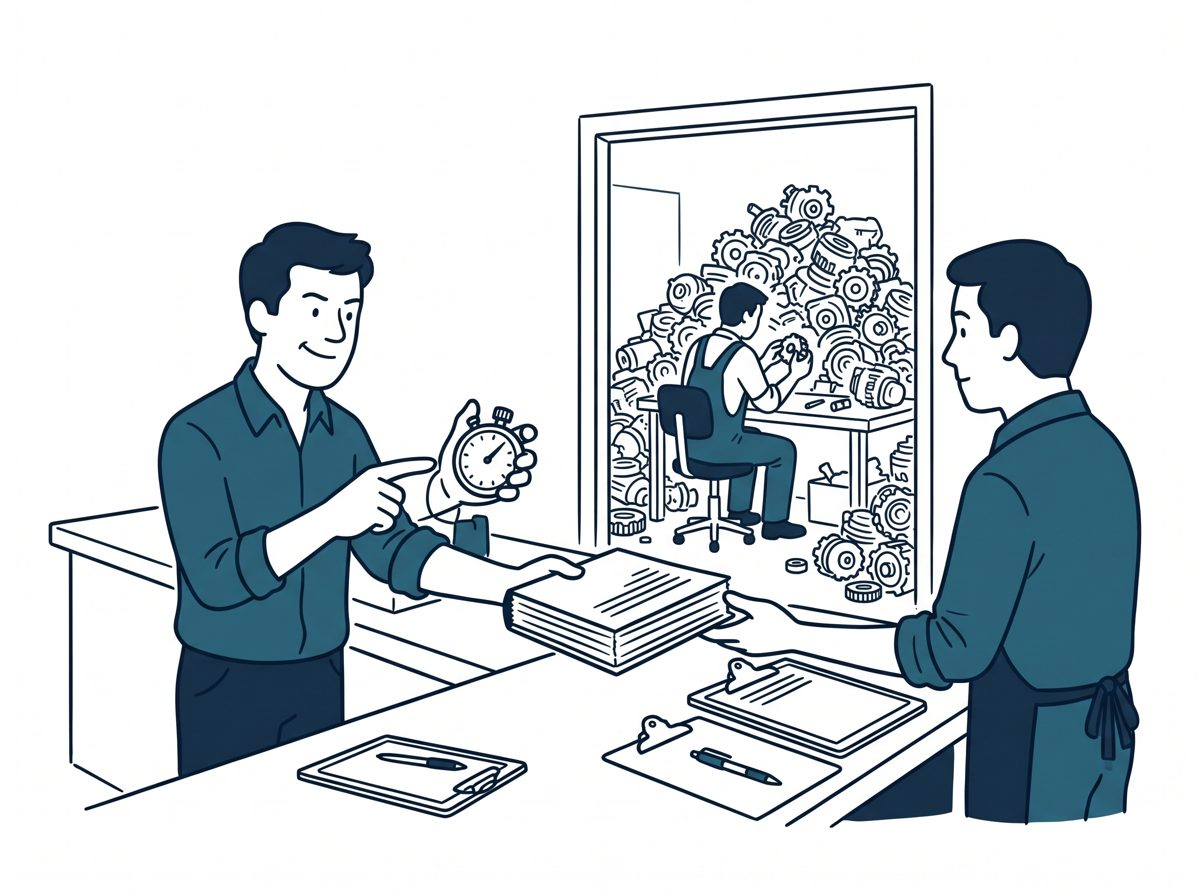<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Die Stoppuhr hält an, sobald der Auftrag am Schalter abgegeben ist. Fertig ist er dann noch nicht. <code style="color:inherit;">torch.cuda.synchronize()</code> wartet, bis die Werkstatt wirklich fertig ist.</div></div>

Zwei weitere Dinge gehören zu einer brauchbaren Messung:

- **Aufwärmen.** Die ersten Aufrufe einer Operation können langsamer sein als die folgenden, weil die GPU Speicher anfordert und Programmteile lädt. Wir rufen die Funktion deshalb einige Male auf, bevor wir stoppen.
- **Median statt Einzelwert.** Auf einem Rechner laufen andere Programme mit, deshalb fallen einzelne Messungen deutlich zu lang aus. Wir messen mehrmals und nehmen den Median, also den mittleren der sortierten Werte. Bei einer geraden Anzahl ist es der Mittelwert der zwei mittleren Werte.

Die Funktion `bench` berücksichtigt alle drei Punkte: Synchronisation, Aufwärmen und Median. Lesen Sie sie Zeile für Zeile. Sie misst die Zeit vom Beginn bis zum Ende des Aufrufs aus Sicht des Python-Programms. Der Aufwand, den der Aufruf selbst verursacht, ist also mitgemessen.

In [ ]:
# Vorgabe: die Messfunktion dieser Lerneinheit — lesen und ausführen
def bench(f, *args, device, warmup=3, repeats=10):
    """Median der Laufzeit von f(*args) in Sekunden, mit Aufwärmen und Synchronisation auf der GPU."""
    on_gpu = torch.device(device).type == "cuda"
    for _ in range(warmup):
        f(*args)
    times = []
    for _ in range(repeats):
        if on_gpu:
            torch.cuda.synchronize()
        start = time.perf_counter()
        f(*args)
        if on_gpu:
            torch.cuda.synchronize()
        times.append(time.perf_counter() - start)
    return statistics.median(times)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: die Messfunktion dieser Lerneinheit — lesen und ausführen</span>
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">bench</span>(f, <span style="color: #666">*</span>args, device, warmup<span style="color: #666">=3</span>, repeats<span style="color: #666">=10</span>):
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Median der Laufzeit von f(*args) in Sekunden, mit Aufwärmen und Synchronisation auf der GPU."""</span>
    on_gpu <span style="color: #666">=</span> torch<span style="color: #666">.</span>device(device)<span style="color: #666">.</span>type <span style="color: #666">==</span> <span style="color: #BA2121">"cuda"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Aufwärmen: Diese Aufrufe werden nicht gestoppt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    <span style="color: #008000; font-weight: bold">for</span> _ <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">range</span>(warmup):
        f(<span style="color: #666">*</span>args)
    times <span style="color: #666">=</span> []
    <span style="color: #008000; font-weight: bold">for</span> _ <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">range</span>(repeats):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; vor dem Start warten, damit keine älteren Aufträge in die Messung fallen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">        <span style="color: #008000; font-weight: bold">if</span> on_gpu:
            torch<span style="color: #666">.</span>cuda<span style="color: #666">.</span>synchronize()
        start <span style="color: #666">=</span> time<span style="color: #666">.</span>perf_counter()
        f(<span style="color: #666">*</span>args)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; vor dem Stopp warten, bis die GPU wirklich fertig ist</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">        <span style="color: #008000; font-weight: bold">if</span> on_gpu:
            torch<span style="color: #666">.</span>cuda<span style="color: #666">.</span>synchronize()
        times<span style="color: #666">.</span>append(time<span style="color: #666">.</span>perf_counter() <span style="color: #666">-</span> start)
    <span style="color: #008000; font-weight: bold">return</span> statistics<span style="color: #666">.</span>median(times)</code></pre></details>

In [ ]:
if device.type == "cuda":
    for n in SIZES:
        x_dev = make_data(n).to(device)
        t = bench(row_l2_normalize_torch, x_dev, device=device)
        print(f"{n:>7} Zeilen: {t * 1000:.3f} ms")
else:
    print("Ohne GPU gibt es hier nichts zu messen. Die Referenzwerte stehen im Text.")

Jetzt wächst die Zeit mit der Eingabe. Bei 100 000 Zeilen liegt die korrekt gemessene Zeit auf der T4 (Google Colab) rund fünfzigmal über dem Wert, den die Messung ohne Synchronisation gezeigt hat.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">8 min</span>✏️ Aufgabe 6.4 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die nächste Zelle enthält drei Messungen. Über jeder steht, was sie messen soll. Jede macht einen anderen Fehler und liefert deshalb eine Zahl, die etwas anderes misst. Finden Sie die drei Fehler und schreiben Sie in der Zelle darunter die korrigierten Fassungen <code style="color:inherit;">measure_a</code>, <code style="color:inherit;">measure_b</code> und <code style="color:inherit;">measure_c</code>. Jede misst mit <code style="color:inherit;">bench</code> und gibt die Zeit in Sekunden zurück.</p>
<p>Der Fehler in C entsteht nur, wenn <code style="color:inherit;">device</code> eine GPU ist. Arbeiten Sie auf der CPU, dann misst C schon in der vorgegebenen Fassung richtig. Erklären Sie in diesem Fall, warum das so ist, und schreiben Sie <code style="color:inherit;">measure_c</code> so, dass die Funktion unabhängig vom gewählten <code style="color:inherit;">device</code> auf der CPU misst.</p>
<p>Wer früher fertig ist: Führen Sie die Zelle nach der Prüfzelle aus. Sie zeigt für jede Messung die fehlerhafte und die korrigierte Zahl. In welche Richtung weicht die fehlerhafte Zahl ab, und warum?</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> A stoppt die Zeit von Hand. B legt in der gestoppten Funktion mehr an als das Ergebnis. C rechnet nicht auf dem Gerät, das die Beschreibung nennt.</p></div></details>
</div>
</div>

In [ ]:
# Vorgabe: drei fehlerhafte Messungen — lesen und ausführen
x_small = make_data(10_000)                    # Messsatz auf der CPU
x_small_dev = x_small.to(device)               # derselbe Messsatz auf dem Device

def measure_a_wrong():
    """Soll messen: den Operator auf 10 000 Zeilen, die schon auf dem Device liegen."""
    start = time.perf_counter()
    row_l2_normalize_torch(x_small_dev)
    return time.perf_counter() - start

def measure_b_wrong():
    """Soll messen: den Operator auf 50 000 Zeilen, die schon auf dem Device liegen."""
    def run():
        x = make_data(50_000).to(device)
        return row_l2_normalize_torch(x)
    return bench(run, device=device)

def measure_c_wrong():
    """Soll messen: den Operator auf 10 000 Zeilen auf der CPU."""
    return bench(row_l2_normalize_torch, x_small_dev, device="cpu")

In [ ]:
def measure_a():
    """Der Operator auf 10 000 Zeilen, die schon auf dem Device liegen."""
    # TODO: Ihre Lösung hier
    ...

def measure_b():
    """Der Operator auf 50 000 Zeilen, die schon auf dem Device liegen."""
    # TODO: Ihre Lösung hier
    ...

def measure_c():
    """Der Operator auf 10 000 Zeilen auf der CPU."""
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen. Sie beobachtet, wie Ihre drei Funktionen bench aufrufen
real_bench, real_make_data, real_operator = bench, make_data, row_l2_normalize_torch
log, made, ops = [], [0], [0]
def traced_make_data(n):
    made[0] += 1
    return real_make_data(n)
def traced_operator(x, *args, **kwargs):
    ops[0] += 1
    return real_operator(x, *args, **kwargs)
def traced_bench(f, *args, device, **kwargs):
    made_before, ops_before = made[0], ops[0]
    result = real_bench(f, *args, device=device, **kwargs)
    log.append({"f": f, "args": args, "device": torch.device(device), "result": result,
                "warmup": kwargs.get("warmup", 3), "repeats": kwargs.get("repeats", 10),
                "made": made[0] - made_before, "ops": ops[0] - ops_before})
    return result

bench, make_data, row_l2_normalize_torch = traced_bench, traced_make_data, traced_operator
try:
    seen = {}
    for name, func in [("measure_a", measure_a), ("measure_b", measure_b), ("measure_c", measure_c)]:
        log.clear()
        seen[name] = (func(), list(log))
finally:
    bench, make_data, row_l2_normalize_torch = real_bench, real_make_data, real_operator

expected = {"measure_a": (10_000, device.type), "measure_b": (50_000, device.type), "measure_c": (10_000, "cpu")}
for name, (rows, where) in expected.items():
    value, calls = seen[name]
    assert isinstance(value, float), f"{name} soll die gemessene Zeit in Sekunden zurückgeben (return vergessen?)"
    assert len(calls) == 1, f"{name} soll genau einmal mit bench messen, gefunden: {len(calls)} Aufrufe von bench"
    call = calls[0]
    assert value == call["result"], f"{name} soll den Messwert von bench unverändert zurückgeben, also in Sekunden"
    assert call["warmup"] >= 1 and call["repeats"] >= 3, f"{name}: bench soll aufwärmen und mehrmals messen. Lassen Sie warmup und repeats auf den Vorgabewerten"
    assert call["made"] == 0, f"{name}: während der Messung werden Daten angelegt. Legen Sie die Daten vor dem Aufruf von bench an"
    assert call["ops"] >= call["warmup"] + call["repeats"], f"{name}: row_l2_normalize_torch läuft nicht bei jedem gemessenen Aufruf. Übergeben Sie bench die Rechnung selbst und nicht ihr fertiges Ergebnis"
    out = call["f"](*call["args"])
    assert isinstance(out, torch.Tensor) and out.shape == (rows, 384), f"{name} soll den Operator auf {rows} Zeilen messen"
    assert abs(torch.sqrt((out[0] * out[0]).sum()).item() - 1.0) < 1e-3, f"{name} soll row_l2_normalize_torch messen: die erste Zeile des Ergebnisses hat nicht die Länge 1"
    assert out.device.type == where, f"{name} soll auf {where} rechnen, die Rechnung läuft auf {out.device.type}"
    assert call["device"].type == where, f"{name}: bench bekommt device={call['device']}, die Daten liegen auf {where}"
print("Alle drei Messungen verwenden bench mit passenden Daten und passendem Device.")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen. Sie beobachtet, wie Ihre drei Funktionen bench aufrufen</span>
real_bench, real_make_data, real_operator <span style="color: #666">=</span> bench, make_data, row_l2_normalize_torch
log, made, ops <span style="color: #666">=</span> [], [<span style="color: #666">0</span>], [<span style="color: #666">0</span>]
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">traced_make_data</span>(n):
    made[<span style="color: #666">0</span>] <span style="color: #666">+=</span> <span style="color: #666">1</span>
    <span style="color: #008000; font-weight: bold">return</span> real_make_data(n)
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">traced_operator</span>(x, <span style="color: #666">*</span>args, <span style="color: #666">**</span>kwargs):
    ops[<span style="color: #666">0</span>] <span style="color: #666">+=</span> <span style="color: #666">1</span>
    <span style="color: #008000; font-weight: bold">return</span> real_operator(x, <span style="color: #666">*</span>args, <span style="color: #666">**</span>kwargs)
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">traced_bench</span>(f, <span style="color: #666">*</span>args, device, <span style="color: #666">**</span>kwargs):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Die Prüfzelle merkt sich je Aufruf von bench: Funktion, Argumente, Device, Messwert und Einstellungen. Sie zählt auch, wie oft währenddessen Daten angelegt wurden und wie oft der Operator lief</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    made_before, ops_before <span style="color: #666">=</span> made[<span style="color: #666">0</span>], ops[<span style="color: #666">0</span>]
    result <span style="color: #666">=</span> real_bench(f, <span style="color: #666">*</span>args, device<span style="color: #666">=</span>device, <span style="color: #666">**</span>kwargs)
    log<span style="color: #666">.</span>append({<span style="color: #BA2121">"f"</span>: f, <span style="color: #BA2121">"args"</span>: args, <span style="color: #BA2121">"device"</span>: torch<span style="color: #666">.</span>device(device), <span style="color: #BA2121">"result"</span>: result,
                <span style="color: #BA2121">"warmup"</span>: kwargs<span style="color: #666">.</span>get(<span style="color: #BA2121">"warmup"</span>, <span style="color: #666">3</span>), <span style="color: #BA2121">"repeats"</span>: kwargs<span style="color: #666">.</span>get(<span style="color: #BA2121">"repeats"</span>, <span style="color: #666">10</span>),
                <span style="color: #BA2121">"made"</span>: made[<span style="color: #666">0</span>] <span style="color: #666">-</span> made_before, <span style="color: #BA2121">"ops"</span>: ops[<span style="color: #666">0</span>] <span style="color: #666">-</span> ops_before})
    <span style="color: #008000; font-weight: bold">return</span> result

bench, make_data, row_l2_normalize_torch <span style="color: #666">=</span> traced_bench, traced_make_data, traced_operator
<span style="color: #008000; font-weight: bold">try</span>:
    seen <span style="color: #666">=</span> {}
    <span style="color: #008000; font-weight: bold">for</span> name, func <span style="color: #A2F; font-weight: bold">in</span> [(<span style="color: #BA2121">"measure_a"</span>, measure_a), (<span style="color: #BA2121">"measure_b"</span>, measure_b), (<span style="color: #BA2121">"measure_c"</span>, measure_c)]:
        log<span style="color: #666">.</span>clear()
        seen[name] <span style="color: #666">=</span> (func(), <span style="color: #008000">list</span>(log))
<span style="color: #008000; font-weight: bold">finally</span>:
    bench, make_data, row_l2_normalize_torch <span style="color: #666">=</span> real_bench, real_make_data, real_operator

expected <span style="color: #666">=</span> {<span style="color: #BA2121">"measure_a"</span>: (<span style="color: #666">10_000</span>, device<span style="color: #666">.</span>type), <span style="color: #BA2121">"measure_b"</span>: (<span style="color: #666">50_000</span>, device<span style="color: #666">.</span>type), <span style="color: #BA2121">"measure_c"</span>: (<span style="color: #666">10_000</span>, <span style="color: #BA2121">"cpu"</span>)}
<span style="color: #008000; font-weight: bold">for</span> name, (rows, where) <span style="color: #A2F; font-weight: bold">in</span> expected<span style="color: #666">.</span>items():
    value, calls <span style="color: #666">=</span> seen[name]
    <span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(value, <span style="color: #008000">float</span>), <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll die gemessene Zeit in Sekunden zurückgeben (return vergessen?)"</span>
    <span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(calls) <span style="color: #666">==</span> <span style="color: #666">1</span>, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll genau einmal mit bench messen, gefunden: </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(calls)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> Aufrufe von bench"</span>
    call <span style="color: #666">=</span> calls[<span style="color: #666">0</span>]
    <span style="color: #008000; font-weight: bold">assert</span> value <span style="color: #666">==</span> call[<span style="color: #BA2121">"result"</span>], <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll den Messwert von bench unverändert zurückgeben, also in Sekunden"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; Aufwärmen und mehrere Wiederholungen müssen erhalten bleiben, sonst ist es wieder eine Einzelmessung</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    <span style="color: #008000; font-weight: bold">assert</span> call[<span style="color: #BA2121">"warmup"</span>] <span style="color: #666">&gt;=</span> <span style="color: #666">1</span> <span style="color: #A2F; font-weight: bold">and</span> call[<span style="color: #BA2121">"repeats"</span>] <span style="color: #666">&gt;=</span> <span style="color: #666">3</span>, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: bench soll aufwärmen und mehrmals messen. Lassen Sie warmup und repeats auf den Vorgabewerten"</span>
    <span style="color: #008000; font-weight: bold">assert</span> call[<span style="color: #BA2121">"made"</span>] <span style="color: #666">==</span> <span style="color: #666">0</span>, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: während der Messung werden Daten angelegt. Legen Sie die Daten vor dem Aufruf von bench an"</span>
    <span style="color: #008000; font-weight: bold">assert</span> call[<span style="color: #BA2121">"ops"</span>] <span style="color: #666">&gt;=</span> call[<span style="color: #BA2121">"warmup"</span>] <span style="color: #666">+</span> call[<span style="color: #BA2121">"repeats"</span>], <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: row_l2_normalize_torch läuft nicht bei jedem gemessenen Aufruf. Übergeben Sie bench die Rechnung selbst und nicht ihr fertiges Ergebnis"</span>
    out <span style="color: #666">=</span> call[<span style="color: #BA2121">"f"</span>](<span style="color: #666">*</span>call[<span style="color: #BA2121">"args"</span>])
    <span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(out, torch<span style="color: #666">.</span>Tensor) <span style="color: #A2F; font-weight: bold">and</span> out<span style="color: #666">.</span>shape <span style="color: #666">==</span> (rows, <span style="color: #666">384</span>), <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll den Operator auf </span><span style="color: #A45A77; font-weight: bold">{</span>rows<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> Zeilen messen"</span>
    <span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(torch<span style="color: #666">.</span>sqrt((out[<span style="color: #666">0</span>] <span style="color: #666">*</span> out[<span style="color: #666">0</span>])<span style="color: #666">.</span>sum())<span style="color: #666">.</span>item() <span style="color: #666">-</span> <span style="color: #666">1.0</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-3</span>, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll row_l2_normalize_torch messen: die erste Zeile des Ergebnisses hat nicht die Länge 1"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; Daten und Argument <code style="color:inherit;">device=</code> müssen zusammenpassen, sonst wartet bench nicht auf die GPU oder misst auf dem falschen Gerät</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    <span style="color: #008000; font-weight: bold">assert</span> out<span style="color: #666">.</span>device<span style="color: #666">.</span>type <span style="color: #666">==</span> where, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll auf </span><span style="color: #A45A77; font-weight: bold">{</span>where<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> rechnen, die Rechnung läuft auf </span><span style="color: #A45A77; font-weight: bold">{</span>out<span style="color: #666">.</span>device<span style="color: #666">.</span>type<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
    <span style="color: #008000; font-weight: bold">assert</span> call[<span style="color: #BA2121">"device"</span>]<span style="color: #666">.</span>type <span style="color: #666">==</span> where, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>name<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: bench bekommt device=</span><span style="color: #A45A77; font-weight: bold">{</span>call[<span style="color: #BA2121">'device'</span>]<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">, die Daten liegen auf </span><span style="color: #A45A77; font-weight: bold">{</span>where<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle drei Messungen verwenden bench mit passenden Daten und passendem Device."</span>)</code></pre></details>

In [ ]:
# Vorgabe: fehlerhafte und korrigierte Messung nebeneinander — einfach ausführen
pairs = [("A", measure_a_wrong, measure_a), ("B", measure_b_wrong, measure_b), ("C", measure_c_wrong, measure_c)]
for name, wrong, right in pairs:
    print(f"Messung {name}: fehlerhaft {wrong() * 1000:8.3f} ms, korrigiert {right() * 1000:8.3f} ms")

Die Ausgabe stammt vom Referenzgerät (Colab mit T4). Messung A zeigt fehlerhaft 0,18 ms statt 0,38 ms, weil die Uhr vor dem Ende der Rechnung stoppt. Beim allerersten Aufruf kann der fehlerhafte Wert auch größer ausfallen als der korrigierte, weil dann das Aufwärmen mitgemessen wird. Messung B zeigt 155 ms statt 1,7 ms. Fast die ganze Zeit entfällt hier auf das Anlegen der Zufallszahlen und die Übertragung. Messung C zeigt 0,05 ms statt 3,5 ms. Das ist die Zeit für das Abgeben des Auftrags an die GPU und nicht die Rechenzeit der CPU.

**Die Übertragung zählt mit.** Bisher lag der Messsatz schon auf der GPU. In einem echten Programm kommen die Daten aus dem Hauptspeicher und müssen erst übertragen werden. Diese Zeit messen wir getrennt, mit einer kleinen Funktion, die nur `x.to(device)` ausführt. Die Dauer von Übertragung und Rechnung zusammen schätzen wir als Summe der zwei Messwerte.

Ob die GPU für eine Aufgabe schneller ist, hängt von der CPU, der GPU, der Auslastung des Rechners und der Größe der Eingabe ab. Die nächste Aufgabe fragt deshalb nach dem, was Sie auf Ihrem Gerät beobachten.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">7 min</span>✏️ Aufgabe 6.4 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Füllen Sie die Messreihe aus. Die Schleife über die drei Größen ist vorgegeben, ebenso der Messsatz <code style="color:inherit;">x</code> auf der CPU und <code style="color:inherit;">x_dev</code> auf dem Device. Ersetzen Sie die drei <code style="color:inherit;">...</code> durch Messungen mit <code style="color:inherit;">bench</code>: <code style="color:inherit;">t_cpu</code> für den Operator auf <code style="color:inherit;">x</code>, <code style="color:inherit;">t_dev</code> für den Operator auf <code style="color:inherit;">x_dev</code> und <code style="color:inherit;">t_transfer</code> für die Funktion <code style="color:inherit;">transfer</code> auf <code style="color:inherit;">x</code>. Achten Sie auf das Argument <code style="color:inherit;">device=</code>. Führen Sie danach die Zelle mit Tabelle und Diagramm aus und beantworten Sie die drei Fragen darunter für Ihre Messung.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">bench(row_l2_normalize_torch, x, device="cpu")</code> misst auf der CPU. Für die zwei anderen Messungen steht <code style="color:inherit;">device=device</code>, damit <code style="color:inherit;">bench</code> auf die GPU wartet. Ohne GPU messen alle drei Zeilen auf der CPU, die Tabelle zeigt dann zweimal dieselbe Größenordnung.</p></div></details>
</div>
</div>

In [ ]:
def transfer(x):
    """Bringt x auf das Device. Nur dafür da, die Übertragung zu messen."""
    return x.to(device)

results = []                                   # je Größe ein Tupel (n, t_cpu, t_dev, t_transfer) in Sekunden
for n in SIZES:
    x = make_data(n)
    x_dev = x.to(device)
    t_cpu = ...        # Operator auf der CPU
    t_dev = ...        # Operator auf dem Device
    t_transfer = ...   # nur die Übertragung
    results.append((n, t_cpu, t_dev, t_transfer))

In [ ]:
# Prüfzelle — einfach ausführen
assert len(results) == len(SIZES) and [r[0] for r in results] == SIZES, "results soll je Größe aus SIZES einen Eintrag haben"
for n, t_cpu, t_dev, t_transfer in results:
    assert all(isinstance(v, float) and v > 0 for v in (t_cpu, t_dev, t_transfer)), f"bei n = {n} fehlt eine Messung oder sie ist nicht positiv"
print("Die Messreihe ist vollständig.")

In [ ]:
# Vorgabe: Tabelle und Diagramm zur Messreihe — einfach ausführen
print(f"{'Zeilen':>8} | {'CPU':>10} | {str(device):>10} | {'Übertragung':>12} | {'Summe, geschätzt':>16}")
for n, t_cpu, t_dev, t_transfer in results:
    print(f"{n:>8} | {t_cpu * 1000:>7.3f} ms | {t_dev * 1000:>7.3f} ms | {t_transfer * 1000:>9.3f} ms | {(t_dev + t_transfer) * 1000:>13.3f} ms")

fig, ax = plt.subplots(figsize=(6, 3.6))
ns = [r[0] for r in results]
ax.plot(ns, [r[1] * 1000 for r in results], marker="o", label="CPU")
ax.plot(ns, [r[2] * 1000 for r in results], marker="o", label=f"{device}, nur Rechnung")
ax.plot(ns, [(r[2] + r[3]) * 1000 for r in results], marker="o", linestyle="--", label=f"{device}, mit Übertragung (geschätzt)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Zeilen")
ax.set_ylabel("Laufzeit in ms")
ax.legend()
plt.show()

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: Tabelle und Diagramm zur Messreihe — einfach ausführen</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #BA2121">'Zeilen'</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;8</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> | </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #BA2121">'CPU'</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;10</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> | </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">str</span>(device)<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;10</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> | </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #BA2121">'Übertragung'</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;12</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> | </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #BA2121">'Summe, geschätzt'</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;16</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
<span style="color: #008000; font-weight: bold">for</span> n, t_cpu, t_dev, t_transfer <span style="color: #A2F; font-weight: bold">in</span> results:
    <span style="color: #008000">print</span>(<span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>n<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;8</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> | </span><span style="color: #A45A77; font-weight: bold">{</span>t_cpu<span style="color: #BBB"> </span><span style="color: #666">*</span><span style="color: #BBB"> </span><span style="color: #666">1000</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;7.3f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> ms | </span><span style="color: #A45A77; font-weight: bold">{</span>t_dev<span style="color: #BBB"> </span><span style="color: #666">*</span><span style="color: #BBB"> </span><span style="color: #666">1000</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;7.3f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> ms | </span><span style="color: #A45A77; font-weight: bold">{</span>t_transfer<span style="color: #BBB"> </span><span style="color: #666">*</span><span style="color: #BBB"> </span><span style="color: #666">1000</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;9.3f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> ms | </span><span style="color: #A45A77; font-weight: bold">{</span>(t_dev<span style="color: #BBB"> </span><span style="color: #666">+</span><span style="color: #BBB"> </span>t_transfer)<span style="color: #BBB"> </span><span style="color: #666">*</span><span style="color: #BBB"> </span><span style="color: #666">1000</span><span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">&gt;13.3f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> ms"</span>)

fig, ax <span style="color: #666">=</span> plt<span style="color: #666">.</span>subplots(figsize<span style="color: #666">=</span>(<span style="color: #666">6</span>, <span style="color: #666">3.6</span>))
ns <span style="color: #666">=</span> [r[<span style="color: #666">0</span>] <span style="color: #008000; font-weight: bold">for</span> r <span style="color: #A2F; font-weight: bold">in</span> results]
ax<span style="color: #666">.</span>plot(ns, [r[<span style="color: #666">1</span>] <span style="color: #666">*</span> <span style="color: #666">1000</span> <span style="color: #008000; font-weight: bold">for</span> r <span style="color: #A2F; font-weight: bold">in</span> results], marker<span style="color: #666">=</span><span style="color: #BA2121">"o"</span>, label<span style="color: #666">=</span><span style="color: #BA2121">"CPU"</span>)
ax<span style="color: #666">.</span>plot(ns, [r[<span style="color: #666">2</span>] <span style="color: #666">*</span> <span style="color: #666">1000</span> <span style="color: #008000; font-weight: bold">for</span> r <span style="color: #A2F; font-weight: bold">in</span> results], marker<span style="color: #666">=</span><span style="color: #BA2121">"o"</span>, label<span style="color: #666">=</span><span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>device<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">, nur Rechnung"</span>)
ax<span style="color: #666">.</span>plot(ns, [(r[<span style="color: #666">2</span>] <span style="color: #666">+</span> r[<span style="color: #666">3</span>]) <span style="color: #666">*</span> <span style="color: #666">1000</span> <span style="color: #008000; font-weight: bold">for</span> r <span style="color: #A2F; font-weight: bold">in</span> results], marker<span style="color: #666">=</span><span style="color: #BA2121">"o"</span>, linestyle<span style="color: #666">=</span><span style="color: #BA2121">"--"</span>, label<span style="color: #666">=</span><span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>device<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">, mit Übertragung (geschätzt)"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Beide Achsen logarithmisch: Die Werte reichen über mehrere Zehnerpotenzen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ax<span style="color: #666">.</span>set_xscale(<span style="color: #BA2121">"log"</span>)
ax<span style="color: #666">.</span>set_yscale(<span style="color: #BA2121">"log"</span>)
ax<span style="color: #666">.</span>set_xlabel(<span style="color: #BA2121">"Zeilen"</span>)
ax<span style="color: #666">.</span>set_ylabel(<span style="color: #BA2121">"Laufzeit in ms"</span>)
ax<span style="color: #666">.</span>legend()
plt<span style="color: #666">.</span>show()</code></pre></details>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Beantworten Sie für Ihre Messreihe: Für welche der drei Größen ist die Rechnung auf der GPU schneller als auf der CPU? Gibt es in Ihrer Messreihe eine Größe, ab der sich die Reihenfolge umkehrt? Und wie ändert sich das Bild, wenn die Übertragung mitzählt?</p>

</div>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Referenzmessung: Colab mit T4</span></div>
<table>
<thead>
<tr>
<th>Zeilen</th>
<th>CPU</th>
<th>GPU ohne Synchronisation</th>
<th>GPU mit <code style="color:inherit;">bench</code></th>
<th>Übertragung</th>
<th>GPU mit Übertragung, geschätzt</th>
</tr>
</thead>
<tbody>
<tr>
<td>1 000</td>
<td>0,39 ms</td>
<td>0,07 ms</td>
<td>0,12 ms</td>
<td>0,44 ms</td>
<td>0,56 ms</td>
</tr>
<tr>
<td>10 000</td>
<td>4,0 ms</td>
<td>0,10 ms</td>
<td>0,39 ms</td>
<td>3,3 ms</td>
<td>3,7 ms</td>
</tr>
<tr>
<td>100 000</td>
<td>178 ms</td>
<td>0,07 ms</td>
<td>3,4 ms</td>
<td>34 ms</td>
<td>38 ms</td>
</tr>
<tr>
<td>1 000 000</td>
<td>1 790 ms</td>
<td>0,07 ms</td>
<td>32 ms</td>
<td>328 ms</td>
<td>360 ms</td>
</tr>
</tbody>
</table>
<p>Gemessen in Colab: GPU Tesla T4, CPU mit einem Thread, PyTorch 2.14.1, Eingabe <code style="color:inherit;">(Zeilen, 384)</code> in <code style="color:inherit;">float32</code>. Die Spalten „CPU“ und „GPU mit <code style="color:inherit;">bench</code>“ messen nur die Rechnung auf Daten, die schon auf dem Gerät liegen: auf der GPU der Median aus zehn Aufrufen nach drei Aufrufen zum Aufwärmen, auf der CPU der Median aus fünf Aufrufen nach einem Aufruf zum Aufwärmen. „Übertragung“ ist der Median aus fünf Übertragungen von der CPU auf die GPU. Die letzte Spalte addiert die zwei getrennt gemessenen Zeiten für Übertragung und Rechnung. Sie ist eine Schätzung für den gemeinsamen Ablauf und keine eigene Messung. Eine Kontrollmessung, die Übertragung und Rechnung in einem Aufruf stoppt, lag auf demselben Gerät bei allen vier Größen 3 bis 9 Prozent über der Summe. Andere CPUs und andere Zahlen von Threads können zu deutlich anderen Laufzeiten auf der CPU führen.</p>

</div>

Drei Beobachtungen aus der Referenzmessung:

- Ohne Synchronisation zeigt die Stoppuhr bei jeder Größe rund 0,07 ms, auch bei einer Million Zeilen. Das ist überwiegend die Zeit für das Abgeben des Auftrags.
- Die Übertragung dauert ab 10 000 Zeilen rund zehnmal so lange wie die Rechnung auf der GPU. Werden die Daten für jede kleine Rechnung neu übertragen, geht der Vorteil der GPU verloren. Daten sollten deshalb einmal auf die GPU gebracht werden und dort bleiben, solange mit ihnen gerechnet wird.
- Die Zeit auf der CPU wächst von 10 000 auf 100 000 Zeilen nicht auf das Zehnfache, sondern auf das 45-Fache. Laufzeiten lassen sich also nicht einfach hochrechnen, man muss sie messen. Woher der Sprung kommt, untersucht die Vertiefung unten.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Warum wächst die Zeit auf der CPU sprunghaft?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Wir haben auf dem Referenzgerät nachgemessen. Bis 10 000 Zeilen braucht der Operator rund 0,4 bis 0,6 ms je 1 000 Zeilen, ab 30 000 Zeilen rund 1,7 bis 2,1 ms. Der Sprung liegt also zwischen 15 MB und 46 MB je Tensor.</p>
<p>Der Operator legt für <code style="color:inherit;">x * x</code> und für das Ergebnis je einen neuen Tensor in der Größe der Eingabe an. Wir haben deshalb die Teilschritte einzeln gemessen, einmal mit neuen Ergebnis-Tensoren und einmal so, dass Multiplikation und Division in vorab angelegte Tensoren schreiben (Argument <code style="color:inherit;">out=</code>). Bei 100 000 Zeilen sinkt die Summe der Teilzeiten damit von rund 173 ms auf 67 ms, bei 10 000 Zeilen ändert sich fast nichts. Das spricht dafür, dass das Bereitstellen des Speichers für große Ergebnisse einen wesentlichen Anteil am Sprung hat. Den ganzen Operator mit vorab angelegten Tensoren haben wir nicht in einem Stück gemessen.</p>
<p>Ein kleinerer Anstieg bleibt auch mit <code style="color:inherit;">out=</code>. Er passt dazu, dass die Daten ab dieser Größe nicht mehr in den schnellen Zwischenspeicher des Prozessors (Cache) passen, der auf diesem Gerät 38,5 MB groß ist. Gemessen haben wir diesen Zusammenhang nicht.</p>

</div>
</div>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Regeln für das Messen auf der GPU</span></div>
<table>
<thead>
<tr>
<th>Regel</th>
<th>Warum</th>
<th>Im Code</th>
</tr>
</thead>
<tbody>
<tr>
<td>erst Korrektheit, dann Zeit</td>
<td>eine schnelle falsche Rechnung ist nichts wert</td>
<td><code style="color:inherit;">torch.allclose(...)</code> gegen die Referenz</td>
</tr>
<tr>
<td>aufwärmen</td>
<td>erste Aufrufe können langsamer sein</td>
<td>einige Aufrufe ohne Stoppuhr</td>
</tr>
<tr>
<td>synchronisieren</td>
<td>Aufrufe kehren zurück, bevor die GPU fertig ist</td>
<td><code style="color:inherit;">torch.cuda.synchronize()</code> vor Start und vor Stopp</td>
</tr>
<tr>
<td>wiederholen und den Median nehmen</td>
<td>einzelne Messungen reißen aus</td>
<td><code style="color:inherit;">statistics.median(times)</code></td>
</tr>
<tr>
<td>Übertragung getrennt ausweisen</td>
<td>sie kann länger dauern als die Rechnung</td>
<td>eigene Messung für <code style="color:inherit;">x.to(device)</code></td>
</tr>
<tr>
<td>das Gerät dazuschreiben</td>
<td>Zeiten ohne Gerät sind nicht vergleichbar</td>
<td>GPU, CPU, Versionen, Form der Eingabe</td>
</tr>
</tbody>
</table>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Eine Million Zeilen</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Wenn die Messreihe auf Ihrem Gerät läuft, können Sie <code style="color:inherit;">SIZES</code> um <code style="color:inherit;">1_000_000</code> ergänzen und die drei Zellen noch einmal ausführen. Rechnen Sie vorher den Speicher nach: Eine Million Zeilen mit 384 Spalten in <code style="color:inherit;">float32</code> sind 1,5 GB, und das ist nur ein Tensor. Dazu kommen das Zwischenergebnis <code style="color:inherit;">x * x</code>, die Ausgabe und die Kopie auf der CPU. In Colab mit T4 reicht der Speicher dafür. Auf dem JupyterHub teilen Sie die GPU mit anderen. Sehen Sie dort vorher nach, wie viel Speicher frei ist (Vertiefung am Ende von Kapitel <a href="#kap-device-cpu-und-gpu">6.3</a>).</p>

</div>
</div>

## <a id="kap-das-erste-modell"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.5&nbsp;&nbsp;Das erste Modell</span>

Wir wechseln vom Operator zu den Titanic-Daten aus LE05. Die nächste Zelle baut in einem Zug nach, was in LE05 entstanden ist: die Trennung in Trainings- und Testteil, die Vorverarbeitung mit `make_preprocessor`, die Tensoren mit `to_tensors`, die Klasse `TitanicDataset` und die zwei `DataLoader`. Die Namen und Werte sind dieselben wie dort. Führen Sie die Zelle aus und vergleichen Sie die Formen mit dem, was Sie aus LE05 kennen: zwölf Zahlenspalten je Passagier, das Ziel als Spalte mit einer 0 oder 1.

In [ ]:
# Vorgabe: der Stand am Ende von LE05 — einfach ausführen
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data/titanic_clean.csv")
num_cols = ["age", "sibsp", "parch", "fare"]
cat_cols = ["sex", "embarked", "pclass"]
X, y = df[num_cols + cat_cols], df["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

def make_preprocessor(num_cols, cat_cols):
    """Vorverarbeitung aus LE05: Lücken füllen, Zahlen skalieren, Kategorien kodieren."""
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

def to_tensors(prep, X_df, y):
    """Wendet die gefittete Vorverarbeitung an und gibt Merkmale (N, 12) und Ziel (N, 1) als float32-Tensoren zurück."""
    X_t = torch.from_numpy(prep.transform(X_df).astype(np.float32))
    y_t = torch.from_numpy(y.to_numpy().astype(np.float32)).reshape(-1, 1)
    return X_t, y_t

class TitanicDataset(Dataset):
    """Gibt die Beispiele einzeln aus: ds[i] ist das Paar aus Merkmalszeile i und Zieleintrag i."""

    def __init__(self, X_t, y_t):
        super().__init__()
        self.X, self.y = X_t, y_t

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        return self.X[i], self.y[i]

prep = make_preprocessor(num_cols, cat_cols).fit(X_train)       # gelernt wird nur aus dem Trainingsteil
X_train_t, y_train_t = to_tensors(prep, X_train, y_train)
X_test_t, y_test_t = to_tensors(prep, X_test, y_test)

torch.manual_seed(0)
train_loader = DataLoader(TitanicDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
test_loader = DataLoader(TitanicDataset(X_test_t, y_test_t), batch_size=64, shuffle=False)
print(X_train_t.shape, y_train_t.shape, X_test_t.shape, y_test_t.shape)
print("Batches je Durchlauf:", len(train_loader))

In LE05 hat die logistische Regression auf diesen Daten 0,805 Accuracy auf dem Testteil erreicht, die Baseline 0,618. Die logistische Regression rechnet für jeden Passagier in zwei Schritten: Sie multipliziert jedes der zwölf Merkmale mit einem Gewicht, addiert alles auf und zählt eine weitere Zahl dazu, den Bias. Aus dem Ergebnis macht die Sigmoid-Funktion eine Wahrscheinlichkeit zwischen 0 und 1.

Den ersten Schritt gibt es in PyTorch als fertigen Baustein. `nn.Linear(12, 1)` ist eine Schicht mit zwölf Eingängen und einem Ausgang. Die Schicht ist ein Objekt mit zwei Attributen: `model.weight` enthält die zwölf Gewichte, `model.bias` den Bias. Beide sind Tensoren. Beim Anlegen werden beide mit kleinen Zufallszahlen gefüllt. Mit `torch.manual_seed(0)` bekommen Sie bei jedem Lauf dieselben Startwerte.

In [ ]:
torch.manual_seed(0)
model = nn.Linear(12, 1)
print(model)
print(model.weight.shape, model.bias.shape)
print(model.weight.requires_grad, X_train_t.requires_grad)

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Parameter</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein <strong>Parameter</strong> ist in PyTorch ein Tensor vom Typ <code style="color:inherit;">nn.Parameter</code>, einer Unterklasse von <code style="color:inherit;">torch.Tensor</code>, der bei einem Modell registriert ist. Parameter enthalten die Werte, die ein Modell im Training lernen kann. Bei unserem Modell sind das die Gewichte und der Bias.</p>
<p>Unser Modell <code style="color:inherit;">nn.Linear(12, 1)</code> hat zwei Parameter. Sie sind als Attribute erreichbar: <code style="color:inherit;">model.weight</code> mit der Form <code style="color:inherit;">(1, 12)</code> und <code style="color:inherit;">model.bias</code> mit der Form <code style="color:inherit;">(1,)</code>, zusammen 13 Zahlen. PyTorch nennt den ganzen Tensor einen Parameter: <code style="color:inherit;">model.weight</code> ist ein Parameter mit zwölf Werten. Im Sprachgebrauch heißen oft auch die einzelnen Zahlen Parameter, etwa in „ein Modell mit 13 Parametern“. Wir sagen dafür Parameterwerte.</p>
<p>Bei unseren Parametern ist <code style="color:inherit;">requires_grad=True</code> gesetzt. Das ist der Standardwert für <code style="color:inherit;">nn.Parameter</code>. Das Training braucht für jeden Parameterwert einen Gradienten, also die Angabe, in welche Richtung und wie stark dieser Wert den Loss verändert (Kapitel <a href="#kap-der-trainings-loop">6.6</a>). Damit PyTorch die Gradienten berechnen kann, muss es mitschreiben, welche Rechnungen mit dem Parameter ausgeführt werden. <code style="color:inherit;">requires_grad=True</code> schaltet dieses Mitschreiben für einen Tensor ein. Für die Eingabedaten brauchen wir in unserem Training keine Gradienten, deshalb ist die Markierung dort nicht gesetzt. Man kann sie auch bei einem Parameter abschalten. Ein solcher Parameter wird nicht mehr trainiert, bleibt aber ein Parameter des Modells.</p>
<p>Die Markierung allein macht einen Tensor nicht zum Parameter eines Modells. Dazu muss er beim Modell registriert sein. Wie das geht, zeigt Kapitel <a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet">6.7</a>.</p>

</div>
</div>

`model.parameters()` liefert die registrierten Parameter eines Modells nacheinander. Die Schicht kennt ihre zwei Tensoren, ohne dass wir sie irgendwo aufgezählt haben. Wie das funktioniert, zeigt Kapitel <a href="#kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet">6.7</a>. Hier nutzen wir den Mechanismus nur.

**Der Vorwärtsdurchlauf.** Ein Modell wird aufgerufen wie eine Funktion: `model(xb)` rechnet für jede Zeile des Batches die gewichtete Summe plus Bias. Wir holen einen Batch aus dem Loader und sehen uns die Formen an.

In [ ]:
torch.manual_seed(0)
xb, yb = next(iter(train_loader))
logits = model(xb)
print(xb.shape, "->", logits.shape)
by_hand = xb @ model.weight.T + model.bias
print(torch.allclose(logits, by_hand))
print(logits[:3])
# Formen: xb (64, 12) @ weight.T (12, 1) -> (64, 1), + bias (1,) -> (64, 1)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">torch<span style="color: #666">.</span>manual_seed(<span style="color: #666">0</span>)
xb, yb <span style="color: #666">=</span> <span style="color: #008000">next</span>(<span style="color: #008000">iter</span>(train_loader))
logits <span style="color: #666">=</span> model(xb)
<span style="color: #008000">print</span>(xb<span style="color: #666">.</span>shape, <span style="color: #BA2121">"-&gt;"</span>, logits<span style="color: #666">.</span>shape)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Die Schicht rechnet nichts anderes als diese Zeile. <code style="color:inherit;">@</code> ist das Matrixprodukt aus LE03</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">by_hand <span style="color: #666">=</span> xb <span style="color: #666">@</span> model<span style="color: #666">.</span>weight<span style="color: #666">.</span>T <span style="color: #666">+</span> model<span style="color: #666">.</span>bias
<span style="color: #008000">print</span>(torch<span style="color: #666">.</span>allclose(logits, by_hand))
<span style="color: #008000">print</span>(logits[:<span style="color: #666">3</span>])
<span style="color: #3D7B7B; font-style: italic"># Formen: xb (64, 12) @ weight.T (12, 1) -&gt; (64, 1), + bias (1,) -&gt; (64, 1)</span></code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Logit</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein <strong>Logit</strong> ist eine reelle Zahl <code style="color:inherit;">z</code>, die über die Sigmoid-Funktion für eine Wahrscheinlichkeit <code style="color:inherit;">p</code> steht: <code style="color:inherit;">p = sigmoid(z) = 1 / (1 + exp(-z))</code>. Umgekehrt gilt <code style="color:inherit;">z = log(p / (1 - p))</code>. Der Logit ist also der Logarithmus des Verhältnisses von Wahrscheinlichkeit und Gegenwahrscheinlichkeit. Ein Logit von 0 entspricht <code style="color:inherit;">p = 0,5</code>. Positive Logits entsprechen Wahrscheinlichkeiten über 0,5, negative Logits Wahrscheinlichkeiten darunter. Je größer der Betrag, desto näher liegt <code style="color:inherit;">p</code> bei 1 oder bei 0.</p>
<p>Unser Modell gibt für jeden Passagier einen Logit aus. <code style="color:inherit;">torch.sigmoid</code> rechnet ihn in die Wahrscheinlichkeit für „überlebt“ um. Für die Entscheidung genügt das Vorzeichen: Ein Logit über 0 bedeutet die Vorhersage „überlebt“, weil die Wahrscheinlichkeit dann über 0,5 liegt. Die Schicht und die Sigmoid-Funktion zusammen ergeben die Rechnung der logistischen Regression.</p>

</div>
</div>

Die nächste Zelle rechnet die Logits des Batches in Wahrscheinlichkeiten um und speichert sie als `probs`. Darunter stehen zum Vergleich die Zielwerte der ersten drei Passagiere.

In [ ]:
probs = torch.sigmoid(logits)
print(probs[:3])
print(yb[:3])

Das Modell ist noch nicht trainiert. Seine Gewichte sind Zufallszahlen und wurden noch nicht anhand der Zielwerte angepasst.

**Der Loss.** Um das Modell zu verbessern, brauchen wir eine Zahl, die sagt, wie schlecht die Vorhersagen eines Batches sind. Diese Zahl heißt Loss, auf Deutsch Verlust. Für eine Ja-Nein-Entscheidung ist der übliche Loss die binäre Kreuzentropie. Sie bestraft eine falsche Vorhersage umso härter, je sicherer sich das Modell dabei war. Ein Modell, das immer 0,5 vorhersagt, bekommt den Wert 0,693. Kleinere Werte sind besser, null wäre eine perfekte und völlig sichere Vorhersage. Wie die Kreuzentropie hergeleitet ist und warum sie zu dieser Aufgabe passt, behandeln die Module zu neuronalen Netzen.

In PyTorch heißt dieser Loss `nn.BCEWithLogitsLoss`. Der Name sagt, was er erwartet: Logits, keine Wahrscheinlichkeiten. Die Sigmoid-Funktion ist in den Loss eingebaut, weil sich beides zusammen numerisch genauer rechnen lässt als nacheinander. Wir geben dem Loss also die Logits (`logits`) und nicht die Wahrscheinlichkeiten (`probs`).

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
loss = loss_fn(logits, yb)
print(loss)
print(loss.shape, loss.item())

Der Loss ist ein Tensor ohne Achsen. Er enthält eine einzige Zahl für den ganzen Batch, den Mittelwert über die 64 Beispiele. In der Ausgabe steht hinter der Zahl der Eintrag `grad_fn=<...>`. Er zeigt, dass PyTorch den Rechenweg aufgezeichnet hat: Der Loss ist aus den Logits entstanden, und die Logits sind aus `model.weight` und `model.bias` entstanden. Aus dieser Aufzeichnung berechnet PyTorch die Gradienten für die zwei Parameter (nächstes Kapitel).

**Die Form des Ziels.** In LE05 haben wir das Ziel in die Form `(N, 1)` gebracht und angekündigt, dass der Loss das verlangt. Jetzt lässt sich zeigen, was sonst passiert: Der Loss vergleicht Vorhersage und Ziel (englisch target oder label) Position für Position und besteht darauf, dass beide dieselbe Form haben.

In [ ]:
try:
    loss_fn(logits, yb.reshape(-1))            # Ziel in der Form (64,) statt (64, 1)
except ValueError as err:
    print("ValueError:", err)

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 6.5 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Notieren Sie sich für jede der fünf Zeilen Ihre Vorhersage (Form oder Anzahl), bevor Sie die Zelle ausführen. Vergleichen Sie danach. <code style="color:inherit;">nn.Linear(n_in, n_out)</code> hat ein Gewicht der Form <code style="color:inherit;">(n_out, n_in)</code> und einen Bias der Form <code style="color:inherit;">(n_out,)</code>. <code style="color:inherit;">numel()</code> gibt die Anzahl der Werte eines Tensors zurück.</p>

</div>
</div>

In [ ]:
layer = nn.Linear(9, 3)
print(layer.weight.shape)
print(layer.bias.shape)
print(layer.weight.numel() + layer.bias.numel())
print(layer(torch.zeros(5, 9)).shape)
print(len(list(layer.parameters())))

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 6.5 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">count_parameters(model)</code>. Sie gibt die Anzahl aller Parameterwerte des Modells zurück, also die Summe von <code style="color:inherit;">numel()</code> über alle Parameter.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">model.parameters()</code> lässt sich in einer <code style="color:inherit;">for</code>-Schleife durchlaufen. Mit <code style="color:inherit;">sum(... for p in model.parameters())</code> passt die Funktion in eine Zeile.</p></div></details>
</div>
</div>

In [ ]:
def count_parameters(model):
    """Gibt die Anzahl der einzelnen Parameterwerte des Modells zurück."""
    # TODO: Ihre Lösung hier
    ...

In [ ]:
print(count_parameters(model))

In [ ]:
# Prüfzelle — einfach ausführen
assert count_parameters(nn.Linear(12, 1)) == 13, "nn.Linear(12, 1) hat 12 Gewichte und einen Bias"
assert count_parameters(nn.Linear(9, 3)) == 30, "nn.Linear(9, 3) hat 27 Gewichte und 3 Bias-Werte"
assert count_parameters(nn.Linear(4, 2, bias=False)) == 8, "ohne Bias bleiben nur die Gewichte (alle Parameter durchlaufen, nicht nur weight und bias)"
assert isinstance(count_parameters(model), int), "das Ergebnis soll eine ganze Python-Zahl sein"

class TwoLayers(nn.Module):
    def __init__(self):
        super().__init__()
        self.first = nn.Linear(4, 3)                    # 12 Gewichte und 3 Bias-Werte
        self.second = nn.Linear(3, 2, bias=False)       # 6 Gewichte

two = TwoLayers()
assert count_parameters(two) == 21, "ein Modell aus zwei Schichten hat hier 15 + 6 = 21 Parameterwerte: model.parameters() durchlaufen, nicht model.weight verwenden"
two.first.weight.requires_grad_(False)
assert count_parameters(two) == 21, "gezählt werden alle Parameterwerte, auch die von Parametern, die gerade nicht trainiert werden"
print("count_parameters zählt richtig.")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">assert</span> count_parameters(nn<span style="color: #666">.</span>Linear(<span style="color: #666">12</span>, <span style="color: #666">1</span>)) <span style="color: #666">==</span> <span style="color: #666">13</span>, <span style="color: #BA2121">"nn.Linear(12, 1) hat 12 Gewichte und einen Bias"</span>
<span style="color: #008000; font-weight: bold">assert</span> count_parameters(nn<span style="color: #666">.</span>Linear(<span style="color: #666">9</span>, <span style="color: #666">3</span>)) <span style="color: #666">==</span> <span style="color: #666">30</span>, <span style="color: #BA2121">"nn.Linear(9, 3) hat 27 Gewichte und 3 Bias-Werte"</span>
<span style="color: #008000; font-weight: bold">assert</span> count_parameters(nn<span style="color: #666">.</span>Linear(<span style="color: #666">4</span>, <span style="color: #666">2</span>, bias<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)) <span style="color: #666">==</span> <span style="color: #666">8</span>, <span style="color: #BA2121">"ohne Bias bleiben nur die Gewichte (alle Parameter durchlaufen, nicht nur weight und bias)"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(count_parameters(model), <span style="color: #008000">int</span>), <span style="color: #BA2121">"das Ergebnis soll eine ganze Python-Zahl sein"</span>

<span style="color: #008000; font-weight: bold">class</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">TwoLayers</span>(nn<span style="color: #666">.</span>Module):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Ein vorgegebenes Testmodell aus zwei Schichten. Wie man solche Klassen schreibt, zeigt Kapitel 6.7</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">__init__</span>(<span style="color: #008000">self</span>):
        <span style="color: #008000">super</span>()<span style="color: #666">.</span><span style="color: #00F">__init__</span>()
        <span style="color: #008000">self</span><span style="color: #666">.</span>first <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">4</span>, <span style="color: #666">3</span>)                    <span style="color: #3D7B7B; font-style: italic"># 12 Gewichte und 3 Bias-Werte</span>
        <span style="color: #008000">self</span><span style="color: #666">.</span>second <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">3</span>, <span style="color: #666">2</span>, bias<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)       <span style="color: #3D7B7B; font-style: italic"># 6 Gewichte</span>

two <span style="color: #666">=</span> TwoLayers()
<span style="color: #008000; font-weight: bold">assert</span> count_parameters(two) <span style="color: #666">==</span> <span style="color: #666">21</span>, <span style="color: #BA2121">"ein Modell aus zwei Schichten hat hier 15 + 6 = 21 Parameterwerte: model.parameters() durchlaufen, nicht model.weight verwenden"</span>
two<span style="color: #666">.</span>first<span style="color: #666">.</span>weight<span style="color: #666">.</span>requires_grad_(<span style="color: #008000; font-weight: bold">False</span>)
<span style="color: #008000; font-weight: bold">assert</span> count_parameters(two) <span style="color: #666">==</span> <span style="color: #666">21</span>, <span style="color: #BA2121">"gezählt werden alle Parameterwerte, auch die von Parametern, die gerade nicht trainiert werden"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"count_parameters zählt richtig."</span>)</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Modell, Logit und Loss</span></div>
<table>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>eine Schicht anlegen</td>
<td><code style="color:inherit;">model = nn.Linear(12, 1)</code></td>
<td>Gewicht <code style="color:inherit;">(1, 12)</code>, Bias <code style="color:inherit;">(1,)</code></td>
</tr>
<tr>
<td>die Parameter durchlaufen</td>
<td><code style="color:inherit;">for p in model.parameters()</code></td>
<td>die registrierten Parameter des Modells</td>
</tr>
<tr>
<td>den Vorwärtsdurchlauf (englisch forward pass) rechnen</td>
<td><code style="color:inherit;">logits = model(xb)</code></td>
<td><code style="color:inherit;">(64, 12)</code> wird zu <code style="color:inherit;">(64, 1)</code></td>
</tr>
<tr>
<td>Logits als Wahrscheinlichkeit lesen</td>
<td><code style="color:inherit;">torch.sigmoid(logits)</code></td>
<td>Werte zwischen 0 und 1</td>
</tr>
<tr>
<td>den Loss anlegen</td>
<td><code style="color:inherit;">loss_fn = nn.BCEWithLogitsLoss()</code></td>
<td>erwartet Logits und ein Ziel derselben Form</td>
</tr>
<tr>
<td>den Loss berechnen</td>
<td><code style="color:inherit;">loss = loss_fn(logits, yb)</code></td>
<td>Tensor ohne Achsen, Mittelwert über den Batch</td>
</tr>
<tr>
<td>die Zahl herausholen</td>
<td><code style="color:inherit;">loss.item()</code></td>
<td>Python-Zahl</td>
</tr>
</tbody>
</table>

</div>

## <a id="kap-der-trainings-loop"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.6&nbsp;&nbsp;Der Trainings-Loop</span>

Training heißt: die Parameter so verändern, dass der Loss kleiner wird.

**Wozu Gradienten?** Der Loss hängt von den Parameterwerten ab. Andere Gewichte ergeben andere Vorhersagen und damit einen anderen Loss. Gesucht sind Werte, bei denen der Loss klein ist. Durchprobieren scheidet aus, schon bei unseren 13 Werten gibt es zu viele Kombinationen. Man stellt deshalb für jeden Parameterwert eine einfachere Frage: Wird der Loss größer oder kleiner, wenn ich nur diesen einen Wert ein wenig erhöhe, und wie stark? Die Antwort ist eine Zahl, der **Gradient** dieses Werts. Ein positiver Gradient bedeutet, dass der Loss steigt, wenn der Wert größer wird. Ein negativer bedeutet, dass der Loss dabei sinkt.

Mit den Gradienten ist klar, was zu tun ist: Jeder Wert wird ein kleines Stück in die Richtung verändert, in der der Loss sinkt. Danach berechnet man neue Gradienten und wiederholt das. Dieses Verfahren heißt Gradientenabstieg. Die Gradienten berechnet PyTorch für uns, das ist die Aufgabe von Autograd.

**Der Ablauf.** Das Training besteht aus vielen kleinen Trainingsschritten, einer je Batch. Ein Batch ist ein Bündel von 64 Beispielen aus dem `DataLoader` (LE05). Jeder Trainingsschritt besteht aus denselben fünf Zeilen, die weiter unten als Tabelle stehen. Wir führen sie zuerst einzeln an einem Batch aus und sehen nach jeder Zeile nach, was sich verändert hat.

Zum Modell und zum Loss kommt ein drittes Objekt, der Optimierer. Er bekommt die Parameter des Modells und verändert sie. Wir verwenden das einfachste Verfahren, `torch.optim.SGD` (stochastic gradient descent, auf Deutsch stochastischer Gradientenabstieg). `lr` ist die Lernrate, sie legt die Schrittweite fest. Den Wert 0,05 geben wir vor.

Wir legen das Modell neu an, damit alle mit denselben Startwerten beginnen.

In [ ]:
torch.manual_seed(0)
model = nn.Linear(12, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)

**Schritt 1 und 2: Vorhersage und Loss.** Das sind die zwei Zeilen aus dem vorigen Kapitel. Jeder Parameter hat ein Attribut `.grad`. Dort legt PyTorch seine Gradienten ab, sobald sie berechnet sind. Nach den ersten zwei Schritten ist das noch nicht geschehen: `.grad` ist `None`.

In [ ]:
logits = model(xb)                       # Schritt 1: Vorhersage
loss = loss_fn(logits, yb)               # Schritt 2: Loss
print("Loss:", loss.item())
print("Gradient:", model.weight.grad)

**Schritt 3 und 4: Gradienten zurücksetzen und berechnen.** Schritt 3 setzt die gespeicherten Gradienten zurück, Schritt 4 berechnet die Gradienten des aktuellen Batches. Wir beginnen mit Schritt 4. `loss.backward()` geht die Aufzeichnung des Rechenwegs vom Loss aus rückwärts durch und berechnet für jeden Parameterwert seinen Gradienten. Das Ergebnis steht danach in `.grad`: Für die zwölf Gewichte sind es zwölf Gradienten, für den Bias einer. Wie PyTorch diese Zahlen berechnet, behandeln wir in der nächsten Lerneinheit. Hier beobachten wir nur, was hineingeht (der Loss) und was herauskommt (ein Gradient je Parameterwert).

Schritt 3 steht davor. `optimizer.zero_grad()` setzt die Gradienten aus dem vorigen Trainingsschritt zurück, damit `backward()` mit leeren Gradienten beginnt. Im ersten Trainingsschritt gibt es noch nichts zurückzusetzen. Was ohne diese Zeile passiert, zeigt der Abschnitt „Warum die Gradienten zurückgesetzt werden“ weiter unten.

Die nächste Zelle führt beide Schritte aus. Ihre erste Zeile legt vorher eine Kopie der Gewichte an, `weight_before`. Mit ihr prüfen wir am Ende der Zelle, ob `backward()` die Gewichte verändert hat. In dieser Zeile trennt `detach()` den Tensor von der Aufzeichnung des Rechenwegs, und `clone()` legt eine unabhängige Kopie der Werte an.

In [ ]:
# Kopie der Gewichte für den Vergleich am Ende der Zelle
weight_before = model.weight.detach().clone()
optimizer.zero_grad()                    # Schritt 3: alte Gradienten zurücksetzen
loss.backward()                          # Schritt 4: Gradienten berechnen
print(model.weight.grad.shape, model.bias.grad.shape)
print(model.weight.grad[0, :4])
print("Gewichte unverändert:", torch.equal(model.weight, weight_before))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Kopie der Gewichte für den Vergleich am Ende der Zelle</span>
weight_before <span style="color: #666">=</span> model<span style="color: #666">.</span>weight<span style="color: #666">.</span>detach()<span style="color: #666">.</span>clone()
optimizer<span style="color: #666">.</span>zero_grad()                    <span style="color: #3D7B7B; font-style: italic"># Schritt 3: alte Gradienten zurücksetzen</span>
loss<span style="color: #666">.</span>backward()                          <span style="color: #3D7B7B; font-style: italic"># Schritt 4: Gradienten berechnen</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">.grad</code> hat dieselbe Form wie der Parameter: ein Gradient je Gewicht</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(model<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad<span style="color: #666">.</span>shape, model<span style="color: #666">.</span>bias<span style="color: #666">.</span>grad<span style="color: #666">.</span>shape)
<span style="color: #008000">print</span>(model<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad[<span style="color: #666">0</span>, :<span style="color: #666">4</span>])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">backward()</code> hat nur die Gradienten geschrieben. Die Gewichte sind unverändert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Gewichte unverändert:"</span>, torch<span style="color: #666">.</span>equal(model<span style="color: #666">.</span>weight, weight_before))</code></pre></details>

**Schritt 5: die Parameter verändern.** `optimizer.step()` verändert die Parameter. SGD rechnet für jeden Parameterwert dieselbe einfache Zeile:

`neuer Wert = alter Wert − Lernrate · Gradient`

Das Minuszeichen sorgt dafür, dass jeder Wert in die Richtung geht, in der der Loss sinkt: Ein positiver Gradient heißt, dass ein größerer Wert den Loss erhöht, also wird der Wert kleiner gemacht. Die Lernrate legt fest, wie weit. Der Gradient gilt nur in der unmittelbaren Umgebung des aktuellen Werts. Eine zu große Änderung kann den Loss deshalb trotzdem erhöhen. Die nächste Zelle rechnet die Zeile für das erste Gewicht von Hand nach und vergleicht mit dem, was `step()` daraus macht.

In [ ]:
w_old = model.weight[0, 0].item()
g = model.weight.grad[0, 0].item()
print("alter Wert:", w_old, "| Gradient:", g)
print("erwartet:  ", w_old - 0.05 * g)
optimizer.step()                         # Schritt 5: Parameter verändern
print("neuer Wert:", model.weight[0, 0].item())

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">w_old <span style="color: #666">=</span> model<span style="color: #666">.</span>weight[<span style="color: #666">0</span>, <span style="color: #666">0</span>]<span style="color: #666">.</span>item()
g <span style="color: #666">=</span> model<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad[<span style="color: #666">0</span>, <span style="color: #666">0</span>]<span style="color: #666">.</span>item()
<span style="color: #008000">print</span>(<span style="color: #BA2121">"alter Wert:"</span>, w_old, <span style="color: #BA2121">"| Gradient:"</span>, g)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"erwartet:  "</span>, w_old <span style="color: #666">-</span> <span style="color: #666">0.05</span> <span style="color: #666">*</span> g)
optimizer<span style="color: #666">.</span>step()                         <span style="color: #3D7B7B; font-style: italic"># Schritt 5: Parameter verändern</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Der neue Wert des ersten Gewichts stimmt bis auf Rundung mit der Rechnung von Hand überein</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"neuer Wert:"</span>, model<span style="color: #666">.</span>weight[<span style="color: #666">0</span>, <span style="color: #666">0</span>]<span style="color: #666">.</span>item())</code></pre></details>

Hat das etwas gebracht? Wir rechnen den Loss für denselben Batch noch einmal aus, mit den veränderten Parametern.

In [ ]:
print("Loss vorher: ", loss.item())
print("Loss nachher:", loss_fn(model(xb), yb).item())

Der Loss ist etwas kleiner geworden. In diesem Beispiel senkt ein einzelner Trainingsschritt den Loss nur wenig. Wir beobachten gleich den Verlauf über viele Trainingsschritte.

<div style="border:2px solid #156082; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#156082; font-weight:bold; font-size:1.08em;">Die fünf Schritte: Was liest und was schreibt jede Zeile?</span></div>
<table>
<thead>
<tr>
<th>Schritt</th>
<th>Code</th>
<th>liest</th>
<th>schreibt</th>
</tr>
</thead>
<tbody>
<tr>
<td>1 Vorhersage</td>
<td><code style="color:inherit;">logits = model(xb)</code></td>
<td>Batch, Parameter</td>
<td><code style="color:inherit;">logits</code></td>
</tr>
<tr>
<td>2 Loss</td>
<td><code style="color:inherit;">loss = loss_fn(logits, yb)</code></td>
<td><code style="color:inherit;">logits</code>, Ziel</td>
<td><code style="color:inherit;">loss</code></td>
</tr>
<tr>
<td>3 Zurücksetzen</td>
<td><code style="color:inherit;">optimizer.zero_grad()</code></td>
<td></td>
<td><code style="color:inherit;">.grad</code> aller Parameter (zurückgesetzt)</td>
</tr>
<tr>
<td>4 Gradienten</td>
<td><code style="color:inherit;">loss.backward()</code></td>
<td><code style="color:inherit;">loss</code> und die Aufzeichnung seiner Entstehung</td>
<td><code style="color:inherit;">.grad</code> aller Parameter</td>
</tr>
<tr>
<td>5 Update</td>
<td><code style="color:inherit;">optimizer.step()</code></td>
<td><code style="color:inherit;">.grad</code>, Lernrate</td>
<td>die Parameter selbst</td>
</tr>
</tbody>
</table>
<p>Nur Schritt 5 verändert die Gewichte. <code style="color:inherit;">backward()</code> verändert die Gradienten, <code style="color:inherit;">zero_grad()</code> setzt die Gradienten zurück und lässt die Gewichte in Ruhe.</p>

</div>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Angenommen, im Loop fehlt die Zeile <code style="color:inherit;">optimizer.step()</code>. Was beobachten Sie am Loss, und warum?</p>

</div>

**Warum die Gradienten zurückgesetzt werden.** `backward()` überschreibt `.grad` nicht, es addiert die neuen Gradienten auf die vorhandenen. Die nächste Zelle zeigt das an einem frischen Modell, dessen Parameter wir nicht verändern: Zwei Rückwärtsdurchläufe mit demselben Batch ergeben genau den doppelten Gradienten.

In [ ]:
torch.manual_seed(0)
demo = nn.Linear(12, 1)
loss_fn(demo(xb), yb).backward()
g_once = demo.weight.grad.clone()
loss_fn(demo(xb), yb).backward()
print(g_once[0, :3])
print(demo.weight.grad[0, :3])
print("doppelt:", torch.allclose(demo.weight.grad, 2 * g_once))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">torch<span style="color: #666">.</span>manual_seed(<span style="color: #666">0</span>)
demo <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">12</span>, <span style="color: #666">1</span>)
loss_fn(demo(xb), yb)<span style="color: #666">.</span>backward()
g_once <span style="color: #666">=</span> demo<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad<span style="color: #666">.</span>clone()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; zweiter Rückwärtsdurchlauf ohne Zurücksetzen: Die neuen Gradienten werden addiert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">loss_fn(demo(xb), yb)<span style="color: #666">.</span>backward()
<span style="color: #008000">print</span>(g_once[<span style="color: #666">0</span>, :<span style="color: #666">3</span>])
<span style="color: #008000">print</span>(demo<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad[<span style="color: #666">0</span>, :<span style="color: #666">3</span>])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"doppelt:"</span>, torch<span style="color: #666">.</span>allclose(demo<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad, <span style="color: #666">2</span> <span style="color: #666">*</span> g_once))</code></pre></details>

Ohne `zero_grad()` enthält `.grad` also die Summe aus dem aktuellen und allen früheren Gradienten, und `step()` rechnet mit dieser Summe. Die Parameter ändern sich dann nicht nach dem Gradienten des aktuellen Batches, sondern nach der Summe aller bisherigen. In unserer Referenzmessung ist der Loss dieses Modells ohne `zero_grad()` nach zwanzig Epochen wieder auf 0,71 gestiegen, mit `zero_grad()` auf 0,48 gefallen.

<div style="break-inside:avoid; page-break-inside:avoid;">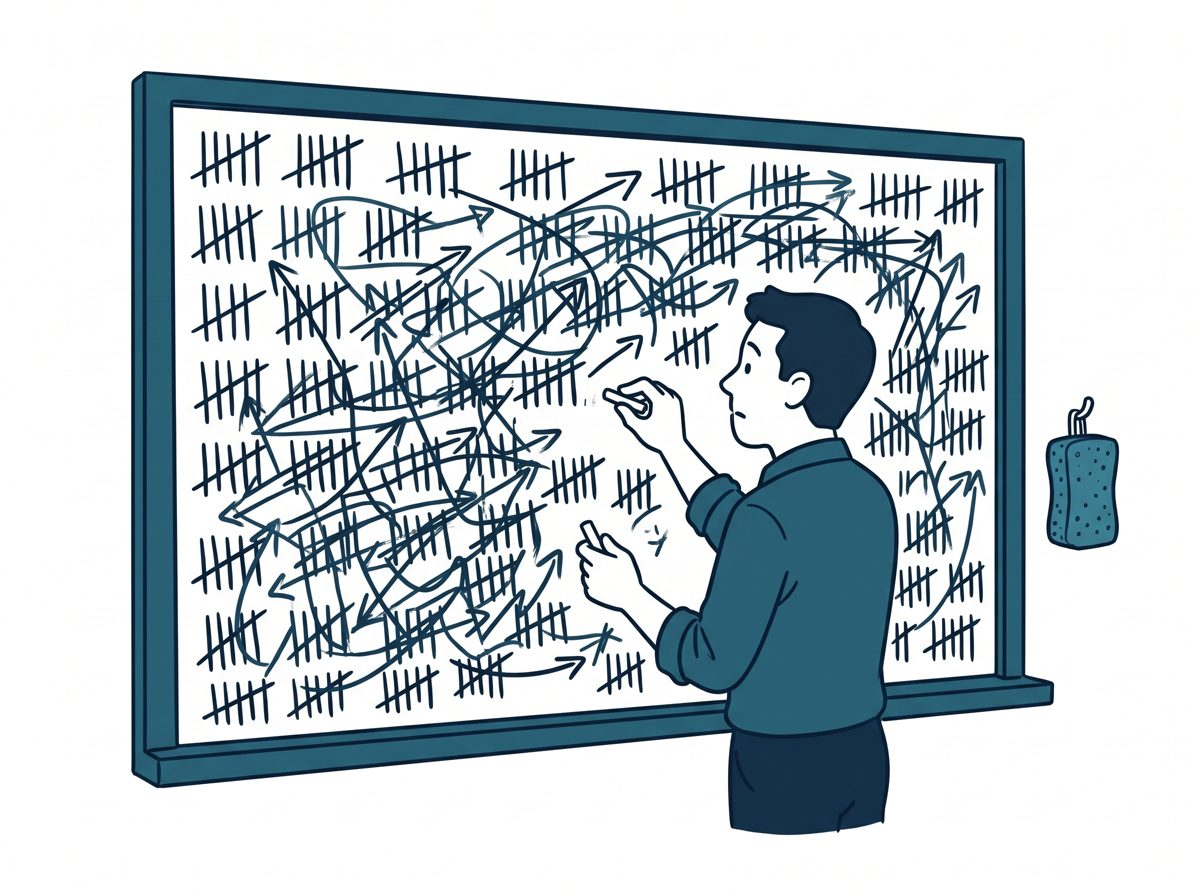<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Vor jedem Durchgang wird die Tafel gewischt. Sonst rechnet der nächste mit den Zahlen aller vorigen weiter. <code style="color:inherit;">optimizer.zero_grad()</code> ist der Schwamm.</div></div>

**Batch, Trainingsschritt und Epoche.** Ein Trainingsschritt verwendet einen Batch. Der Trainingsteil hat 1 047 Beispiele, bei einer Batchgröße von 64 sind das 17 Batches: 16 volle und ein letzter mit 23 Beispielen. Ein Durchlauf durch alle Batches heißt Epoche und besteht hier aus 17 Trainingsschritten. Danach hat das Modell jedes Beispiel einmal gesehen. Für ein brauchbares Ergebnis reicht das nicht, wir lassen deshalb mehrere Epochen laufen. `shuffle=True` im Loader sorgt dafür, dass die Batches in jeder Epoche anders zusammengesetzt sind.

Warum Batches und nicht alle Beispiele auf einmal? Bei unseren 1 047 Beispielen ginge beides. Bei großen Datensätzen können die Daten und die Zwischenwerte der Rechnung jedoch den Speicher der GPU überschreiten. Batches begrenzen den Speicherbedarf und erlauben mehrere Trainingsschritte je Durchlauf durch die Daten.

Eine Epoche schreiben wir als Funktion. Sie macht drei Dinge zusätzlich zu den fünf Schritten:

- Sie ruft am Anfang `model.train()` auf. Das schaltet das Modell in den Trainingsmodus. Für unsere Modelle ändert das nichts an der Rechnung. Bei größeren Netzen verhalten sich einzelne Schichten im Training anders als bei der Bewertung. Ein Beispiel ist die Dropout-Schicht: Sie setzt im Training zufällig einen Teil der Werte auf null und reicht bei der Bewertung alle Werte durch. Der Aufruf steht am Anfang der Funktion, also einmal je Epoche und nicht je Batch. Einmal ganz am Anfang des Trainings würde nicht genügen, weil die Bewertung zwischen zwei Epochen das Modell in den Bewertungsmodus schalten kann.
- Sie bringt jeden Batch mit `.to(device)` auf das Device des Modells.
- Sie gibt den mittleren Loss je Beispiel zurück. Weil der letzte Batch kleiner ist, darf man nicht einfach die 17 Loss-Werte mitteln: Der Loss jedes Batches wird mit der Zahl seiner Beispiele multipliziert, am Ende wird durch die Gesamtzahl geteilt. Die Parameter ändern sich dabei von Batch zu Batch. Der Rückgabewert ist deshalb ein Mittel über die Epoche und nicht genau der Loss des Modells am Ende der Epoche.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">12 min</span>✏️ Aufgabe 6.6 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Vervollständigen Sie <code style="color:inherit;">train_one_epoch</code>. Vorgegeben sind der Kopf, <code style="color:inherit;">model.train()</code>, die Schleife über den Loader und die Rückgabe. Es fehlt das Innere der Schleife: Bringen Sie den Batch auf das Device, führen Sie die fünf Schritte in der richtigen Reihenfolge aus und aktualisieren Sie <code style="color:inherit;">total</code> und <code style="color:inherit;">n</code>.</p>
<p>Wer früher fertig ist: Was gibt die Funktion zurück, wenn Sie <code style="color:inherit;">total += loss.item()</code> schreiben und am Ende durch <code style="color:inherit;">len(loader)</code> teilen? Unter welcher Bedingung ist das Ergebnis sicher dasselbe?</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die fünf Schritte stehen im Kasten oben. <code style="color:inherit;">loss.item()</code> ist der mittlere Loss des Batches, <code style="color:inherit;">len(xb)</code> die Zahl seiner Beispiele. <code style="color:inherit;">total</code> sammelt die Summe der Loss-Werte aller Beispiele, <code style="color:inherit;">n</code> die Zahl der Beispiele.</p></div></details>
</div>
</div>

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    """Trainiert das Modell eine Epoche lang und gibt den mittleren Loss je Beispiel zurück."""
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        # TODO: Ihre Lösung hier
        ...
    return total / n

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu train_one_epoch</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def train_one_epoch(model, loader, loss_fn, optimizer, device):&#10;    &quot;&quot;&quot;Trainiert das Modell eine Epoche lang und gibt den mittleren Loss je Beispiel zurück.&quot;&quot;&quot;&#10;    model.train()&#10;    total, n = 0.0, 0&#10;    for xb, yb in loader:&#10;        xb, yb = xb.to(device), yb.to(device)&#10;        logits = model(xb)&#10;        loss = loss_fn(logits, yb)&#10;        optimizer.zero_grad()&#10;        loss.backward()&#10;        optimizer.step()&#10;        total += loss.item() * len(xb)&#10;        n += len(xb)&#10;    return total / n</pre></details>

In [ ]:
# Prüfzelle — einfach ausführen. Sie arbeitet mit eigenen kleinen Modellen, Ihr Modell bleibt unberührt
torch.manual_seed(1)
X_probe, y_probe = torch.randn(10, 3), (torch.rand(10, 1) > 0.5).to(torch.float32)
probe_loader = DataLoader(TitanicDataset(X_probe, y_probe), batch_size=4, shuffle=False)    # Batches mit 4, 4 und 2 Beispielen
probe = nn.Linear(3, 1)
probe.eval()
value = train_one_epoch(probe, probe_loader, nn.BCEWithLogitsLoss(), torch.optim.SGD(probe.parameters(), lr=0.0), "cpu")
assert isinstance(value, float), "train_one_epoch soll eine Python-Zahl zurückgeben (loss.item() verwendet?)"
assert probe.training, "am Anfang der Funktion soll model.train() stehen"
expected = nn.BCEWithLogitsLoss()(probe(X_probe), y_probe).item()
assert abs(value - expected) < 1e-5, "der Rückgabewert soll der mittlere Loss je Beispiel sein: Batch-Loss mal Batchgröße summieren, durch die Zahl der Beispiele teilen"
g_last = torch.autograd.grad(nn.BCEWithLogitsLoss()(probe(X_probe[8:]), y_probe[8:]), probe.weight)[0]
g_now = probe.weight.grad
cleared = g_now is None or not g_now.any()               # zurückgesetzt, falls zero_grad() nach step() steht
assert cleared or torch.allclose(g_now, g_last, atol=1e-6), "in .grad steht die Summe mehrerer Batches: fehlt optimizer.zero_grad()?"
tiny = nn.Linear(1, 1)
with torch.no_grad():
    tiny.weight.fill_(0.0)
    tiny.bias.fill_(0.0)
tiny_loader = DataLoader(TitanicDataset(torch.tensor([[1.0], [2.0], [-1.0], [3.0]]), torch.tensor([[1.0], [1.0], [0.0], [0.0]])),
                         batch_size=2, shuffle=False)
tiny_value = train_one_epoch(tiny, tiny_loader, nn.BCEWithLogitsLoss(), torch.optim.SGD(tiny.parameters(), lr=0.1), "cpu")
w_tiny, b_tiny = tiny.weight.item(), tiny.bias.item()
assert (w_tiny, b_tiny) != (0.0, 0.0), "die Parameter haben sich nicht verändert: fehlt loss.backward() oder optimizer.step()?"
assert abs(w_tiny - 0.01444) < 1e-4 and abs(b_tiny + 0.00310) < 1e-4, (
    f"nach zwei Trainingsschritten sind Gewicht 0.01444 und Bias -0.00310 erwartet, nicht {w_tiny:.5f} und {b_tiny:.5f}: "
    "Jeder Trainingsschritt muss den Gradienten seines eigenen Batches verwenden (backward vor step, zero_grad vor backward)")
assert abs(tiny_value - 0.72677) < 1e-4, "der mittlere Loss dieser Epoche sollte 0.72677 sein"
if device.type == "cuda":
    probe_dev = nn.Linear(3, 1).to(device)
    train_one_epoch(probe_dev, probe_loader, nn.BCEWithLogitsLoss(), torch.optim.SGD(probe_dev.parameters(), lr=0.1), device)
print("train_one_epoch besteht alle Prüfungen.")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen. Sie arbeitet mit eigenen kleinen Modellen, Ihr Modell bleibt unberührt</span>
torch<span style="color: #666">.</span>manual_seed(<span style="color: #666">1</span>)
X_probe, y_probe <span style="color: #666">=</span> torch<span style="color: #666">.</span>randn(<span style="color: #666">10</span>, <span style="color: #666">3</span>), (torch<span style="color: #666">.</span>rand(<span style="color: #666">10</span>, <span style="color: #666">1</span>) <span style="color: #666">&gt;</span> <span style="color: #666">0.5</span>)<span style="color: #666">.</span>to(torch<span style="color: #666">.</span>float32)
probe_loader <span style="color: #666">=</span> DataLoader(TitanicDataset(X_probe, y_probe), batch_size<span style="color: #666">=4</span>, shuffle<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)    <span style="color: #3D7B7B; font-style: italic"># Batches mit 4, 4 und 2 Beispielen</span>
probe <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">3</span>, <span style="color: #666">1</span>)
probe<span style="color: #666">.</span>eval()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Lernrate 0: Die Parameter bleiben stehen. Der mittlere Loss der Epoche muss dann der Loss über alle zehn Beispiele sein</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">value <span style="color: #666">=</span> train_one_epoch(probe, probe_loader, nn<span style="color: #666">.</span>BCEWithLogitsLoss(), torch<span style="color: #666">.</span>optim<span style="color: #666">.</span>SGD(probe<span style="color: #666">.</span>parameters(), lr<span style="color: #666">=0.0</span>), <span style="color: #BA2121">"cpu"</span>)
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(value, <span style="color: #008000">float</span>), <span style="color: #BA2121">"train_one_epoch soll eine Python-Zahl zurückgeben (loss.item() verwendet?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> probe<span style="color: #666">.</span>training, <span style="color: #BA2121">"am Anfang der Funktion soll model.train() stehen"</span>
expected <span style="color: #666">=</span> nn<span style="color: #666">.</span>BCEWithLogitsLoss()(probe(X_probe), y_probe)<span style="color: #666">.</span>item()
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(value <span style="color: #666">-</span> expected) <span style="color: #666">&lt;</span> <span style="color: #666">1e-5</span>, <span style="color: #BA2121">"der Rückgabewert soll der mittlere Loss je Beispiel sein: Batch-Loss mal Batchgröße summieren, durch die Zahl der Beispiele teilen"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; Nach der Epoche darf in .grad höchstens der Gradient des letzten Batches stehen, nicht die Summe über alle Batches</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">g_last <span style="color: #666">=</span> torch<span style="color: #666">.</span>autograd<span style="color: #666">.</span>grad(nn<span style="color: #666">.</span>BCEWithLogitsLoss()(probe(X_probe[<span style="color: #666">8</span>:]), y_probe[<span style="color: #666">8</span>:]), probe<span style="color: #666">.</span>weight)[<span style="color: #666">0</span>]
g_now <span style="color: #666">=</span> probe<span style="color: #666">.</span>weight<span style="color: #666">.</span>grad
cleared <span style="color: #666">=</span> g_now <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #008000; font-weight: bold">None</span> <span style="color: #A2F; font-weight: bold">or</span> <span style="color: #A2F; font-weight: bold">not</span> g_now<span style="color: #666">.</span>any()               <span style="color: #3D7B7B; font-style: italic"># zurückgesetzt, falls zero_grad() nach step() steht</span>
<span style="color: #008000; font-weight: bold">assert</span> cleared <span style="color: #A2F; font-weight: bold">or</span> torch<span style="color: #666">.</span>allclose(g_now, g_last, atol<span style="color: #666">=1e-6</span>), <span style="color: #BA2121">"in .grad steht die Summe mehrerer Batches: fehlt optimizer.zero_grad()?"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; Zwei Trainingsschritte mit bekanntem Ergebnis: Gewicht und Bias starten bei 0, Lernrate 0.1, zwei Batches mit je zwei Beispielen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">tiny <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">1</span>, <span style="color: #666">1</span>)
<span style="color: #008000; font-weight: bold">with</span> torch<span style="color: #666">.</span>no_grad():
    tiny<span style="color: #666">.</span>weight<span style="color: #666">.</span>fill_(<span style="color: #666">0.0</span>)
    tiny<span style="color: #666">.</span>bias<span style="color: #666">.</span>fill_(<span style="color: #666">0.0</span>)
tiny_loader <span style="color: #666">=</span> DataLoader(TitanicDataset(torch<span style="color: #666">.</span>tensor([[<span style="color: #666">1.0</span>], [<span style="color: #666">2.0</span>], [<span style="color: #666">-1.0</span>], [<span style="color: #666">3.0</span>]]), torch<span style="color: #666">.</span>tensor([[<span style="color: #666">1.0</span>], [<span style="color: #666">1.0</span>], [<span style="color: #666">0.0</span>], [<span style="color: #666">0.0</span>]])),
                         batch_size<span style="color: #666">=2</span>, shuffle<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)
tiny_value <span style="color: #666">=</span> train_one_epoch(tiny, tiny_loader, nn<span style="color: #666">.</span>BCEWithLogitsLoss(), torch<span style="color: #666">.</span>optim<span style="color: #666">.</span>SGD(tiny<span style="color: #666">.</span>parameters(), lr<span style="color: #666">=0.1</span>), <span style="color: #BA2121">"cpu"</span>)
w_tiny, b_tiny <span style="color: #666">=</span> tiny<span style="color: #666">.</span>weight<span style="color: #666">.</span>item(), tiny<span style="color: #666">.</span>bias<span style="color: #666">.</span>item()
<span style="color: #008000; font-weight: bold">assert</span> (w_tiny, b_tiny) <span style="color: #666">!=</span> (<span style="color: #666">0.0</span>, <span style="color: #666">0.0</span>), <span style="color: #BA2121">"die Parameter haben sich nicht verändert: fehlt loss.backward() oder optimizer.step()?"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(w_tiny <span style="color: #666">-</span> <span style="color: #666">0.01444</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-4</span> <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">abs</span>(b_tiny <span style="color: #666">+</span> <span style="color: #666">0.00310</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-4</span>, (
    <span style="color: #BA2121">f"nach zwei Trainingsschritten sind Gewicht 0.01444 und Bias -0.00310 erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>w_tiny<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">.5f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> und </span><span style="color: #A45A77; font-weight: bold">{</span>b_tiny<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">.5f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: "</span>
    <span style="color: #BA2121">"Jeder Trainingsschritt muss den Gradienten seines eigenen Batches verwenden (backward vor step, zero_grad vor backward)"</span>)
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(tiny_value <span style="color: #666">-</span> <span style="color: #666">0.72677</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-4</span>, <span style="color: #BA2121">"der mittlere Loss dieser Epoche sollte 0.72677 sein"</span>
<span style="color: #008000; font-weight: bold">if</span> device<span style="color: #666">.</span>type <span style="color: #666">==</span> <span style="color: #BA2121">"cuda"</span>:
    probe_dev <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">3</span>, <span style="color: #666">1</span>)<span style="color: #666">.</span>to(device)
    train_one_epoch(probe_dev, probe_loader, nn<span style="color: #666">.</span>BCEWithLogitsLoss(), torch<span style="color: #666">.</span>optim<span style="color: #666">.</span>SGD(probe_dev<span style="color: #666">.</span>parameters(), lr<span style="color: #666">=0.1</span>), device)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"train_one_epoch besteht alle Prüfungen."</span>)</code></pre></details>

Jetzt trainieren wir das Modell 20 Epochen lang und merken uns den mittleren Loss jeder Epoche. Lernrate und Zahl der Epochen sind vorgegeben. Beide Werte haben wir für dieses Workbook vorab bestimmt, und zwar mit einem zurückgehaltenen Teil der Trainingsdaten und nicht mit dem Testteil. Das Modell legen wir neu an, damit die Änderungen aus der Demo der einzelnen Schritte oben nicht mitzählen.

In [ ]:
torch.manual_seed(0)
model = nn.Linear(12, 1).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
losses = []
for epoch in range(20):
    losses.append(train_one_epoch(model, train_loader, loss_fn, optimizer, device))
print("Loss nach Epoche 1: ", round(losses[0], 4))
print("Loss nach Epoche 20:", round(losses[-1], 4))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">torch<span style="color: #666">.</span>manual_seed(<span style="color: #666">0</span>)
model <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">12</span>, <span style="color: #666">1</span>)<span style="color: #666">.</span>to(device)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Der Optimierer wird nach <code style="color:inherit;">model.to(device)</code> angelegt, damit er die Parameter auf dem richtigen Device bekommt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">optimizer <span style="color: #666">=</span> torch<span style="color: #666">.</span>optim<span style="color: #666">.</span>SGD(model<span style="color: #666">.</span>parameters(), lr<span style="color: #666">=0.05</span>)
losses <span style="color: #666">=</span> []
<span style="color: #008000; font-weight: bold">for</span> epoch <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">range</span>(<span style="color: #666">20</span>):
    losses<span style="color: #666">.</span>append(train_one_epoch(model, train_loader, loss_fn, optimizer, device))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Loss nach Epoche 1: "</span>, <span style="color: #008000">round</span>(losses[<span style="color: #666">0</span>], <span style="color: #666">4</span>))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Loss nach Epoche 20:"</span>, <span style="color: #008000">round</span>(losses[<span style="color: #666">-1</span>], <span style="color: #666">4</span>))</code></pre></details>

Zwanzig Zahlen liest man am besten als Kurve. Die Referenzkarte zu Matplotlib fasst die Befehle zusammen.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(1, len(losses) + 1), losses, marker="o")
ax.set_xlabel("Epoche")
ax.set_ylabel("mittlerer Loss im Training")
ax.set_xticks(range(2, len(losses) + 1, 2))
plt.show()

Die Kurve fällt am Anfang schnell und wird dann flacher. Mit anderen Einstellungen, etwa einer zu großen Lernrate, kann der Loss auch schwanken oder steigen.

**Bewerten.** Die Kurve zeigt den Loss auf den Trainingsdaten. Sie beantwortet nicht, wie gut das Modell Passagiere vorhersagt, die es nie gesehen hat. Dafür haben wir in LE05 den Testteil zurückgelegt. Wir verwenden dieselbe Metrik wie dort, die Accuracy: den Anteil der richtigen Vorhersagen.

Die Bewertung ist eine eigene Schleife über den Test-Loader. Sie unterscheidet sich in drei Punkten vom Training:

- `model.eval()` schaltet das Modell in den Bewertungsmodus, das Gegenstück zu `model.train()`.
- `with torch.no_grad():` schaltet die Aufzeichnung für die Gradienten ab. Bei der Bewertung wird nichts gelernt, die Aufzeichnung würde nur Zeit und Speicher kosten. `model.eval()` und `torch.no_grad()` sind zwei verschiedene Schalter: Der eine betrifft das Verhalten des Modells, der andere die Buchführung von PyTorch.
- Statt des Loss zählen wir Treffer. Die Vorhersage ist 1, wenn der Logit über 0 liegt, sonst 0. `(logits > 0)` liefert für jeden Passagier `True` oder `False`. Das Ziel `yb` enthält dagegen die Zahlen 1.0 und 0.0. `.to(torch.float32)` wandelt die Wahrheitswerte in dieselben Zahlen um. Danach vergleicht `pred == yb` Vorhersage und Ziel Position für Position.

Auch hier gilt: Die Treffer werden über alle Batches summiert und am Ende durch die Zahl der Beispiele geteilt.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">8 min</span>✏️ Aufgabe 6.6 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">evaluate(model, loader, device)</code>. Die Funktion gibt die Accuracy des Modells auf den Daten des Loaders zurück, als Python-Zahl zwischen 0 und 1. Vorgegeben sind der Kopf, <code style="color:inherit;">model.eval()</code> und der <code style="color:inherit;">with</code>-Block. Ergänzen Sie die Schleife und die Rückgabe.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Der Aufbau ist der von <code style="color:inherit;">train_one_epoch</code>, ohne Loss und ohne die Schritte 3 bis 5. Die Treffer eines Batches zählt <code style="color:inherit;">(pred == yb).sum().item()</code>.</p></div></details>
</div>
</div>

In [ ]:
def evaluate(model, loader, device):
    """Gibt die Accuracy des Modells auf den Daten des Loaders zurück."""
    model.eval()
    correct, n = 0, 0
    with torch.no_grad():
        # TODO: Ihre Lösung hier
        ...
    return correct / n

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu evaluate</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def evaluate(model, loader, device):&#10;    &quot;&quot;&quot;Gibt die Accuracy des Modells auf den Daten des Loaders zurück.&quot;&quot;&quot;&#10;    model.eval()&#10;    correct, n = 0, 0&#10;    with torch.no_grad():&#10;        for xb, yb in loader:&#10;            xb, yb = xb.to(device), yb.to(device)&#10;            pred = (model(xb) &gt; 0).to(torch.float32)&#10;            correct += (pred == yb).sum().item()&#10;            n += len(xb)&#10;    return correct / n</pre></details>

In [ ]:
# Prüfzelle — einfach ausführen. Sie arbeitet mit einem eigenen kleinen Modell, dessen Vorhersagen man im Kopf nachrechnen kann
fixed = nn.Linear(1, 1)
with torch.no_grad():
    fixed.weight.fill_(1.0)
    fixed.bias.fill_(0.0)
X_fixed = torch.tensor([[-2.0], [-0.2], [0.0], [0.2], [2.0]])     # Vorhersagen bei Logit > 0: 0, 0, 0, 1, 1
y_fixed = torch.tensor([[0.0], [0.0], [1.0], [1.0], [1.0]])       # Treffer:                    ja, ja, nein, ja, ja
fixed_loader = DataLoader(TitanicDataset(X_fixed, y_fixed), batch_size=2, shuffle=False)
grad_modes = []
hook = fixed.register_forward_hook(lambda module, inputs, output: grad_modes.append(torch.is_grad_enabled()))
fixed.train()
try:
    acc_check = evaluate(fixed, fixed_loader, "cpu")
finally:
    hook.remove()
assert isinstance(acc_check, float), "evaluate soll eine Python-Zahl zurückgeben"
assert abs(acc_check - 0.8) < 1e-9, (f"erwartet 0.8 (vier von fünf richtig), nicht {acc_check}: Vorhersage 1 genau dann, wenn der Logit über 0 liegt, "
                                     "Treffer über alle Batches summieren und durch die Zahl der Beispiele teilen")
assert not fixed.training, "am Anfang der Funktion soll model.eval() stehen"
assert grad_modes and not any(grad_modes), "die Vorhersagen sollen innerhalb von torch.no_grad() berechnet werden"
if device.type == "cuda":
    fixed_dev = nn.Linear(1, 1).to(device)
    with torch.no_grad():
        fixed_dev.weight.fill_(1.0)
        fixed_dev.bias.fill_(0.0)
    assert abs(evaluate(fixed_dev, fixed_loader, device) - 0.8) < 1e-9, "auf der GPU stimmt das Ergebnis nicht: werden die Batches auf das Device gebracht?"
print("evaluate zählt richtig.")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen. Sie arbeitet mit einem eigenen kleinen Modell, dessen Vorhersagen man im Kopf nachrechnen kann</span>
fixed <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">1</span>, <span style="color: #666">1</span>)
<span style="color: #008000; font-weight: bold">with</span> torch<span style="color: #666">.</span>no_grad():</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Gewicht 1 und Bias 0: Der Logit ist der Eingabewert selbst. <code style="color:inherit;">fill_</code> schreibt einen Wert in alle Stellen eines Tensors</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    fixed<span style="color: #666">.</span>weight<span style="color: #666">.</span>fill_(<span style="color: #666">1.0</span>)
    fixed<span style="color: #666">.</span>bias<span style="color: #666">.</span>fill_(<span style="color: #666">0.0</span>)
X_fixed <span style="color: #666">=</span> torch<span style="color: #666">.</span>tensor([[<span style="color: #666">-2.0</span>], [<span style="color: #666">-0.2</span>], [<span style="color: #666">0.0</span>], [<span style="color: #666">0.2</span>], [<span style="color: #666">2.0</span>]])     <span style="color: #3D7B7B; font-style: italic"># Vorhersagen bei Logit &gt; 0: 0, 0, 0, 1, 1</span>
y_fixed <span style="color: #666">=</span> torch<span style="color: #666">.</span>tensor([[<span style="color: #666">0.0</span>], [<span style="color: #666">0.0</span>], [<span style="color: #666">1.0</span>], [<span style="color: #666">1.0</span>], [<span style="color: #666">1.0</span>]])       <span style="color: #3D7B7B; font-style: italic"># Treffer:                    ja, ja, nein, ja, ja</span>
fixed_loader <span style="color: #666">=</span> DataLoader(TitanicDataset(X_fixed, y_fixed), batch_size<span style="color: #666">=2</span>, shuffle<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; Der Haken notiert bei jedem Vorwärtsdurchlauf, ob PyTorch gerade für Gradienten mitschreibt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">grad_modes <span style="color: #666">=</span> []
hook <span style="color: #666">=</span> fixed<span style="color: #666">.</span>register_forward_hook(<span style="color: #008000; font-weight: bold">lambda</span> module, inputs, output: grad_modes<span style="color: #666">.</span>append(torch<span style="color: #666">.</span>is_grad_enabled()))
fixed<span style="color: #666">.</span>train()
<span style="color: #008000; font-weight: bold">try</span>:
    acc_check <span style="color: #666">=</span> evaluate(fixed, fixed_loader, <span style="color: #BA2121">"cpu"</span>)
<span style="color: #008000; font-weight: bold">finally</span>:
    hook<span style="color: #666">.</span>remove()
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(acc_check, <span style="color: #008000">float</span>), <span style="color: #BA2121">"evaluate soll eine Python-Zahl zurückgeben"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(acc_check <span style="color: #666">-</span> <span style="color: #666">0.8</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-9</span>, (<span style="color: #BA2121">f"erwartet 0.8 (vier von fünf richtig), nicht </span><span style="color: #A45A77; font-weight: bold">{</span>acc_check<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: Vorhersage 1 genau dann, wenn der Logit über 0 liegt, "</span>
                                     <span style="color: #BA2121">"Treffer über alle Batches summieren und durch die Zahl der Beispiele teilen"</span>)
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #A2F; font-weight: bold">not</span> fixed<span style="color: #666">.</span>training, <span style="color: #BA2121">"am Anfang der Funktion soll model.eval() stehen"</span>
<span style="color: #008000; font-weight: bold">assert</span> grad_modes <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000">any</span>(grad_modes), <span style="color: #BA2121">"die Vorhersagen sollen innerhalb von torch.no_grad() berechnet werden"</span>
<span style="color: #008000; font-weight: bold">if</span> device<span style="color: #666">.</span>type <span style="color: #666">==</span> <span style="color: #BA2121">"cuda"</span>:
    fixed_dev <span style="color: #666">=</span> nn<span style="color: #666">.</span>Linear(<span style="color: #666">1</span>, <span style="color: #666">1</span>)<span style="color: #666">.</span>to(device)
    <span style="color: #008000; font-weight: bold">with</span> torch<span style="color: #666">.</span>no_grad():
        fixed_dev<span style="color: #666">.</span>weight<span style="color: #666">.</span>fill_(<span style="color: #666">1.0</span>)
        fixed_dev<span style="color: #666">.</span>bias<span style="color: #666">.</span>fill_(<span style="color: #666">0.0</span>)
    <span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">abs</span>(evaluate(fixed_dev, fixed_loader, device) <span style="color: #666">-</span> <span style="color: #666">0.8</span>) <span style="color: #666">&lt;</span> <span style="color: #666">1e-9</span>, <span style="color: #BA2121">"auf der GPU stimmt das Ergebnis nicht: werden die Batches auf das Device gebracht?"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"evaluate zählt richtig."</span>)</code></pre></details>

In [ ]:
acc = evaluate(model, test_loader, device)
print("Accuracy auf dem Testteil:", round(acc, 3))
print("richtig vorhergesagt:", round(acc * len(X_test_t)), "von", len(X_test_t))

Damit lässt sich das Ergebnis neben die zwei Zahlen aus LE05 stellen:

| Modell | Accuracy auf dem Testteil | richtig von 262 |
|---|---|---|
| Baseline (immer „nicht überlebt“) | 0,618 | 162 |
| logistische Regression aus scikit-learn | 0,805 | 211 |
| `nn.Linear(12, 1)`, selbst trainiert | 0,821 | 215 |

Unser Modell rechnet dieselbe Formel wie die logistische Regression aus LE05 und erreicht eine ähnliche Accuracy. Die Werte sind nicht gleich, weil sich das Training unterscheidet: scikit-learn verwendet ein anderes Verfahren, rechnet bis zu einem Abbruchkriterium und hält die Gewichte in der Standardeinstellung zusätzlich klein (Regularisierung). Wir haben nach zwanzig Epochen aufgehört und lassen die Regularisierung weg. Der Unterschied beträgt vier Passagiere. Bei 262 Testbeispielen ist das zu wenig, um ein Verfahren besser zu nennen als das andere. Auf einem anderen Rechner kann Ihr Wert um ein oder zwei Treffer abweichen.

Längeres Training hat in einem zusätzlichen Lauf mit derselben Lernrate keine höhere Accuracy gebracht. Der Loss der Epoche sank noch von etwa 0,48 auf 0,464 und veränderte sich ab ungefähr 200 Epochen kaum noch. Auf dem Testteil lagen dann 210 oder 211 Vorhersagen richtig. Mehr Epochen führten in diesem Versuch also zu einem etwas kleineren Loss auf den Trainingsdaten, aber nicht zu mehr Treffern auf dem Testteil.

Wichtiger als die genaue Zahl ist der Weg dorthin: Sie haben die Trainingsschleife selbst zusammengesetzt und ihre fünf Schritte einzeln nachvollzogen. Loss, Gradientenberechnung und Optimierer kommen weiter aus der Bibliothek.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Trainieren und Bewerten</span></div>
<table>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Bemerkung</th>
</tr>
</thead>
<tbody>
<tr>
<td>den Optimierer anlegen</td>
<td><code style="color:inherit;">optimizer = torch.optim.SGD(model.parameters(), lr=0.05)</code></td>
<td>nach <code style="color:inherit;">model.to(device)</code></td>
</tr>
<tr>
<td>Trainingsmodus einschalten</td>
<td><code style="color:inherit;">model.train()</code></td>
<td>am Anfang jeder Trainings-Epoche</td>
</tr>
<tr>
<td>Gradienten zurücksetzen</td>
<td><code style="color:inherit;">optimizer.zero_grad()</code></td>
<td>vor jedem <code style="color:inherit;">backward()</code></td>
</tr>
<tr>
<td>Gradienten berechnen</td>
<td><code style="color:inherit;">loss.backward()</code></td>
<td>schreibt <code style="color:inherit;">.grad</code>, addiert auf Vorhandenes</td>
</tr>
<tr>
<td>Parameter verändern</td>
<td><code style="color:inherit;">optimizer.step()</code></td>
<td>neuer Wert = alter Wert − Lernrate · Gradient</td>
</tr>
<tr>
<td>den Loss als Zahl festhalten</td>
<td><code style="color:inherit;">loss.item()</code></td>
<td>für Historie und Ausgabe</td>
</tr>
<tr>
<td>Bewertungsmodus einschalten</td>
<td><code style="color:inherit;">model.eval()</code></td>
<td>am Anfang jeder Bewertung</td>
</tr>
<tr>
<td>ohne Gradienten rechnen</td>
<td><code style="color:inherit;">with torch.no_grad():</code></td>
<td>bei der Bewertung</td>
</tr>
<tr>
<td>aus Logits Entscheidungen machen</td>
<td><code style="color:inherit;">(logits &gt; 0).to(torch.float32)</code></td>
<td>Logit über 0 entspricht Wahrscheinlichkeit über 0,5</td>
</tr>
</tbody>
</table>

</div>

## <a id="kap-ein-zweites-modell-und-wie-nn-module-seine-parameter-findet"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">6.7&nbsp;&nbsp;Ein zweites Modell und wie nn.Module seine Parameter findet</span>

Die Trainingsfunktion weiß nichts über das Innere des Modells. Sie ruft `model(xb)` auf und überlässt dem Optimierer die Parameter. Wir können das Modell deshalb austauschen, ohne an `train_one_epoch` oder `evaluate` etwas zu ändern.

Das zweite Modell ist ein kleines neuronales Netz mit einer verborgenen Schicht. Es rechnet in drei Stufen: Eine erste Schicht macht aus den zwölf Merkmalen 16 Zwischenwerte. Die Funktion ReLU setzt alle negativen Zwischenwerte auf null und lässt die positiven unverändert. Eine zweite Schicht macht aus den 16 Zwischenwerten einen Logit. Ohne die ReLU-Funktion dazwischen ließen sich die zwei Schichten zu einer einzigen zusammenfassen, das Netz könnte dann nicht mehr berechnen als `nn.Linear(12, 1)`.

Ein eigenes Modell schreibt man als Klasse, die von `nn.Module` erbt. Das Muster kennen Sie von `TitanicDataset`: `__init__` ruft zuerst `super().__init__()` auf und legt dann an, was das Objekt braucht, hier die zwei Schichten. Die Methode `forward` beschreibt den Vorwärtsdurchlauf. Lesen Sie die Klasse und führen Sie die Zelle aus.

In [ ]:
class TinyNet(nn.Module):
    """Ein Netz mit einer verborgenen Schicht: 12 Merkmale -> 16 Zwischenwerte -> 1 Logit."""

    def __init__(self, n_in=12, n_hidden=16):
        super().__init__()
        self.hidden = nn.Linear(n_in, n_hidden)
        self.out = nn.Linear(n_hidden, 1)

    def forward(self, x):
        h = torch.relu(self.hidden(x))        # (B, 12) -> (B, 16), negative Werte werden 0
        return self.out(h)                    # (B, 16) -> (B, 1)

torch.manual_seed(0)
net = TinyNet()
print(net)
print("Parameterwerte:", count_parameters(net))

Die erste Schicht hat 12 · 16 Gewichte und 16 Bias-Werte, die zweite 16 Gewichte und einen Bias, zusammen 225 Parameterwerte. Das Training ist dieselbe Schleife wie vorhin, mit einer anderen vorgegebenen Lernrate.

In [ ]:
torch.manual_seed(0)
net = TinyNet().to(device)
optimizer = torch.optim.SGD(net.parameters(), lr=0.5)
net_losses = [train_one_epoch(net, train_loader, loss_fn, optimizer, device) for epoch in range(20)]
net_acc = evaluate(net, test_loader, device)
print("Loss nach Epoche 1: ", round(net_losses[0], 4), "| nach Epoche 20:", round(net_losses[-1], 4))
print("Accuracy auf dem Testteil:", round(net_acc, 3))

Der Loss im Training ist mit 0,42 niedriger als bei der einen Schicht (0,48). Auf dem Testteil liegt das Netz mit 0,809 (212 von 262) trotzdem drei Treffer hinter `nn.Linear(12, 1)`. Beides passt zusammen: Ein Modell mit mehr Parametern kann sich enger an die Trainingsdaten anpassen, und das hilft bei neuen Beispielen nicht automatisch. Drei Treffer Unterschied bei 262 Beispielen belegen in keiner Richtung, dass eines der Modelle besser ist. Für diese Daten bringt die verborgene Schicht jedenfalls keinen sichtbaren Gewinn. Wann ein größeres Netz hilft und wie man das sauber untersucht, ist Stoff der Module zu neuronalen Netzen.

**Woher kennt das Modell seine Parameter?** In `TinyNet` steht nirgends eine Liste der Parameter. `__init__` weist zwei Schichten zu, mehr nicht. Trotzdem liefert `net.parameters()` vier Tensoren, der Optimierer findet sie alle, und `net.to(device)` hat sie alle auf das Device gebracht.

In [ ]:
for name, p in net.named_parameters():
    print(name, tuple(p.shape))

Die Erklärung liegt in einer Sondermethode, die Sie noch nicht kennen: `__setattr__`. Python ruft sie bei jeder Zuweisung an ein Attribut auf. Die Zeile `self.hidden = nn.Linear(...)` wird zu `self.__setattr__("hidden", nn.Linear(...))`. Normalerweise legt diese Methode den Wert einfach im Objekt ab. Eine Klasse kann sie aber selbst schreiben und bei jeder Zuweisung etwas Zusätzliches tun.

`nn.Module` tut genau das: Bei jeder Zuweisung prüft es, was da zugewiesen wird. Ist der Wert ein Parameter, trägt es ihn in ein Dict namens `_parameters` ein. Ist der Wert selbst ein Modul, trägt es ihn in ein Dict namens `_modules` ein. Dieses Eintragen heißt Registrierung. Die zwei Dicts kann man ansehen.

In [ ]:
print(list(net._modules))
print(list(net.hidden._parameters))
print(list(net._parameters))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Die zwei Zuweisungen in <code style="color:inherit;">TinyNet.__init__</code> haben zwei Einträge in <code style="color:inherit;">_modules</code> hinterlassen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #008000">list</span>(net<span style="color: #666">.</span>_modules))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; Die Schicht <code style="color:inherit;">hidden</code> ist selbst ein Modul. Beim Anlegen hat sie ihre zwei Parameter in ihr eigenes Dict <code style="color:inherit;">_parameters</code> eingetragen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #008000">list</span>(net<span style="color: #666">.</span>hidden<span style="color: #666">.</span>_parameters))
<span style="color: #008000">print</span>(<span style="color: #008000">list</span>(net<span style="color: #666">.</span>_parameters))</code></pre></details>

`net` selbst hat keine eigenen Parameter, sein Dict `_parameters` ist leer. Es hat zwei Teilmodule, und jedes davon hat zwei Parameter. `parameters()` geht die Dicts durch: erst die eigenen Parameter, dann die der Teilmodule, und findet so alle vier. Die Namen in der Ausgabe von `named_parameters()` oben (`hidden.weight`) sind der Weg durch diese Dicts.

Jetzt wird auch klar, warum wir `super().__init__()` in `__init__` zuerst aufrufen: Dort entstehen die zwei Dicts. Sie müssen da sein, bevor ein Parameter oder ein Teilmodul zugewiesen wird. Fehlt der Aufruf, bricht schon die erste Zuweisung einer Schicht mit einer Fehlermeldung ab.

Die Registrierung hat eine Grenze, die sich aus diesem Mechanismus ergibt: Sie sieht nur, was direkt einem Attribut zugewiesen wird. Wer ein Netz mit vielen Schichten baut, legt die Schichten gern in eine Liste, etwa `self.layers = [nn.Linear(12, 16), nn.Linear(16, 1)]`. Eine gewöhnliche Python-Liste ist aber weder ein Parameter noch ein Modul, die Zuweisung registriert deshalb nichts. Rechnen kann man mit solchen Schichten trotzdem. Nur findet `parameters()` sie nicht: Der Optimierer bekommt sie nicht, sie werden nicht trainiert, und `to(device)` lässt sie auf der CPU zurück.

Die zwei Klassen in der nächsten Zelle zeigen den Unterschied. Sie sind auf die Registrierung gekürzt. Ein vollständiges Modell hätte zusätzlich die Methode `forward`. Für die Frage, was `parameters()` findet, spielt sie keine Rolle.

In [ ]:
class ListNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(12, 16), nn.Linear(16, 1)]               # gewöhnliche Liste

class ModuleListNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(12, 16), nn.Linear(16, 1)])   # Liste, die selbst ein Modul ist

print(count_parameters(ListNet()), count_parameters(ModuleListNet()))

`ListNet` meldet null Parameter. Schon das Anlegen eines Optimierers bricht bei diesem Modell ab, weil er eine leere Parameterliste bekommt. Gefährlicher ist der gemischte Fall: Hat ein Modell daneben registrierte Schichten, bekommt der Optimierer nur diese. Die Schichten in der Liste werden dann ohne Fehlermeldung nicht trainiert, und `to(device)` lässt sie auf der CPU. `nn.ModuleList` ist eine Liste, die selbst ein Modul ist. Sie wird deshalb registriert, und ihre Einträge werden mitregistriert.

Dasselbe gilt für einzelne Tensoren: Ein gewöhnlicher Tensor als Attribut wird kein Parameter, auch nicht mit `requires_grad=True`. Erst `nn.Parameter(tensor)` macht ihn dazu. Die Schichten von PyTorch verpacken ihre Gewichte auf diese Weise.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 6.7 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Wie viele Parameter-Tensoren findet <code style="color:inherit;">parameters()</code> in jeder der drei Klassen? Notieren Sie sich Ihre drei Vorhersagen, bevor Sie die Zelle ausführen. Vergleichen Sie danach.</p>

</div>
</div>

In [ ]:
class NetA(nn.Module):
    def __init__(self):
        super().__init__()
        self.first = nn.Linear(4, 4)
        self.second = nn.Linear(4, 4, bias=False)

class NetB(nn.Module):
    def __init__(self):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(1))
        self.offset = torch.zeros(1)

class NetC(nn.Module):
    def __init__(self):
        super().__init__()
        self.inner = NetA()
        self.head = nn.Linear(4, 1)

print(len(list(NetA().parameters())))
print(len(list(NetB().parameters())))
print(len(list(NetC().parameters())))

**Was aus der Registrierung folgt.** Drei Dinge, die Sie in dieser Lerneinheit verwendet haben, gehen auf die zwei Dicts zurück:

- `model.parameters()` liefert die registrierten Parameter, auch die aller Teilmodule. Der Optimierer bekommt sie beim Anlegen.
- `model.to(device)` bringt alle registrierten Parameter auf das Device.
- `model.state_dict()` liefert ein Dict mit den Namen und Werten der registrierten Parameter. Damit speichert und lädt man ein trainiertes Modell.

Neben Parametern kann ein Modul weitere Tensoren registrieren, die nicht trainiert werden (Puffer, englisch buffers). Ein Beispiel sind die laufenden Mittelwerte einer Normalisierungsschicht: Sie gehören zum Zustand des Modells, werden aber nicht über Gradienten angepasst. `to(device)` bringt auch sie auf das Device, `state_dict()` enthält diejenigen, die zum Speichern vorgesehen sind. Unsere Modelle haben keine.

Ein viertes Detail gehört nicht zur Registrierung, wird aber oft damit verwechselt: Warum führt `model(x)` die Methode `forward` aus? Python übersetzt den Aufruf `model(x)` in `model.__call__(x)`. Die Sondermethode `__call__` macht ein Objekt aufrufbar wie eine Funktion. Unsere Klasse `TinyNet` definiert sie nicht selbst, sie erbt sie von `nn.Module`. Dort ruft `__call__` die Methode `self.forward(x)` auf. Davor und danach führt es Hooks aus: Funktionen, die Werkzeuge an ein Modul hängen können und die bei jedem Aufruf mitlaufen. Wer `model.forward(x)` direkt aufruft, überspringt sie. Deshalb schreiben wir in eigenen Modellen die Methode `forward`, rufen das Modell aber immer mit `model(x)` auf.

Die zwei Mechanismen beantworten also verschiedene Fragen. Die Registrierung erklärt, wie das Modell seine Parameter findet. `__call__` erklärt, wie der Aufruf zur Rechnung führt.

Grundkurs Teil 4 behandelt beide Sondermethoden ausführlich. Die Vertiefung unten baut die Registrierung in dreißig Zeilen nach.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Eigene Modelle mit nn.Module</span></div>
<table>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Bemerkung</th>
</tr>
</thead>
<tbody>
<tr>
<td>ein eigenes Modell schreiben</td>
<td><code style="color:inherit;">class TinyNet(nn.Module):</code></td>
<td>mit <code style="color:inherit;">__init__</code> und <code style="color:inherit;">forward</code></td>
</tr>
<tr>
<td>die Basisklasse einrichten</td>
<td><code style="color:inherit;">super().__init__()</code></td>
<td>zuerst aufrufen: legt die zwei Dicts an, bevor etwas zugewiesen wird</td>
</tr>
<tr>
<td>eine Schicht registrieren</td>
<td><code style="color:inherit;">self.hidden = nn.Linear(12, 16)</code></td>
<td>die Zuweisung an ein Attribut genügt</td>
</tr>
<tr>
<td>mehrere Schichten in einer Liste halten</td>
<td><code style="color:inherit;">self.layers = nn.ModuleList([...])</code></td>
<td>eine gewöhnliche Liste wird nicht registriert</td>
</tr>
<tr>
<td>einen eigenen Parameter anlegen</td>
<td><code style="color:inherit;">self.scale = nn.Parameter(torch.ones(1))</code></td>
<td>ein gewöhnlicher Tensor wird nicht registriert</td>
</tr>
<tr>
<td>das Modell aufrufen</td>
<td><code style="color:inherit;">model(x)</code></td>
<td>führt <code style="color:inherit;">forward(x)</code> aus</td>
</tr>
<tr>
<td>Namen und Formen der Parameter ansehen</td>
<td><code style="color:inherit;">model.named_parameters()</code></td>
<td>Paare aus Name und Tensor</td>
</tr>
<tr>
<td>den Zustand als Dict holen</td>
<td><code style="color:inherit;">model.state_dict()</code></td>
<td>zum Speichern und Laden</td>
</tr>
</tbody>
</table>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Die Registrierung in dreißig Zeilen nachgebaut</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Das Prinzip lässt sich ohne PyTorch nachbauen. Die nächste Zelle enthält ein Lehrmodell mit zwei eigenen Klassen <code style="color:inherit;">MiniParameter</code> und <code style="color:inherit;">MiniModule</code>. Lesen Sie es in drei Schritten: Im Konstruktor entstehen die zwei Dicts. <code style="color:inherit;">__setattr__</code> fängt jede Zuweisung ab, trägt Parameter und Teilmodule ein und legt den Wert danach wie üblich ab. <code style="color:inherit;">parameters()</code> sammelt die eigenen Parameter ein und fragt danach jedes Teilmodul. <code style="color:inherit;">MiniLinear</code> und <code style="color:inherit;">MiniNet</code> verwenden das Lehrmodell so, wie <code style="color:inherit;">nn.Linear</code> und <code style="color:inherit;">TinyNet</code> die Klasse <code style="color:inherit;">nn.Module</code> verwenden. Überlegen Sie vor dem Ausführen: In welchem Dict landet <code style="color:inherit;">self.hidden = MiniLinear(12, 16)</code>, und in welchem <code style="color:inherit;">self.bias = MiniParameter(...)</code>?</p>

</div>
</div>

In [ ]:
# Zur Vertiefung
class MiniParameter:
    """Platzhalter für einen Parameter: ein Name für eine Liste von Werten."""
    def __init__(self, values):
        self.values = values

class MiniModule:
    """Lehrmodell: merkt sich bei jeder Zuweisung Parameter und Teilmodule."""

    def __init__(self):
        object.__setattr__(self, "_parameters", {})
        object.__setattr__(self, "_modules", {})

    def __setattr__(self, name, value):
        if isinstance(value, MiniParameter):
            self._parameters[name] = value
        elif isinstance(value, MiniModule):
            self._modules[name] = value
        object.__setattr__(self, name, value)

    def parameters(self):
        found = list(self._parameters.values())
        for child in self._modules.values():           # Teilmodule nach ihren Parametern fragen
            found += child.parameters()
        return found

class MiniLinear(MiniModule):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.weight = MiniParameter([0.0] * (n_in * n_out))
        self.bias = MiniParameter([0.0] * n_out)

class MiniNet(MiniModule):
    def __init__(self):
        super().__init__()
        self.hidden = MiniLinear(12, 16)
        self.out = MiniLinear(16, 1)

mini = MiniNet()
print(list(mini._modules))
print(list(mini.hidden._parameters))
print(len(mini.parameters()), "Parameter gefunden")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Zur Vertiefung</span>
<span style="color: #008000; font-weight: bold">class</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">MiniParameter</span>:
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Platzhalter für einen Parameter: ein Name für eine Liste von Werten."""</span>
    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">__init__</span>(<span style="color: #008000">self</span>, values):
        <span style="color: #008000">self</span><span style="color: #666">.</span>values <span style="color: #666">=</span> values

<span style="color: #008000; font-weight: bold">class</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">MiniModule</span>:
<span style="color: #BBB">    </span><span style="color: #BA2121; font-style: italic">"""Lehrmodell: merkt sich bei jeder Zuweisung Parameter und Teilmodule."""</span>

    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">__init__</span>(<span style="color: #008000">self</span>):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Die zwei Dicts legen wir direkt über <code style="color:inherit;">object.__setattr__</code> an, an der eigenen Methode vorbei. Sie sollen selbst nicht geprüft werden</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">        <span style="color: #008000">object</span><span style="color: #666">.</span><span style="color: #00F">__setattr__</span>(<span style="color: #008000">self</span>, <span style="color: #BA2121">"_parameters"</span>, {})
        <span style="color: #008000">object</span><span style="color: #666">.</span><span style="color: #00F">__setattr__</span>(<span style="color: #008000">self</span>, <span style="color: #BA2121">"_modules"</span>, {})

    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">__setattr__</span>(<span style="color: #008000">self</span>, name, value):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; Python ruft diese Methode bei jeder Zuweisung <code style="color:inherit;">self.name = value</code> auf</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">        <span style="color: #008000; font-weight: bold">if</span> <span style="color: #008000">isinstance</span>(value, MiniParameter):
            <span style="color: #008000">self</span><span style="color: #666">.</span>_parameters[name] <span style="color: #666">=</span> value
        <span style="color: #008000; font-weight: bold">elif</span> <span style="color: #008000">isinstance</span>(value, MiniModule):
            <span style="color: #008000">self</span><span style="color: #666">.</span>_modules[name] <span style="color: #666">=</span> value</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; Danach wird der Wert wie üblich im Objekt abgelegt. <code style="color:inherit;">self.name = value</code> an dieser Stelle würde dieselbe Methode wieder aufrufen, ohne Ende</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">        <span style="color: #008000">object</span><span style="color: #666">.</span><span style="color: #00F">__setattr__</span>(<span style="color: #008000">self</span>, name, value)

    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">parameters</span>(<span style="color: #008000">self</span>):
        found <span style="color: #666">=</span> <span style="color: #008000">list</span>(<span style="color: #008000">self</span><span style="color: #666">.</span>_parameters<span style="color: #666">.</span>values())
        <span style="color: #008000; font-weight: bold">for</span> child <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">self</span><span style="color: #666">.</span>_modules<span style="color: #666">.</span>values():           <span style="color: #3D7B7B; font-style: italic"># Teilmodule nach ihren Parametern fragen</span>
            found <span style="color: #666">+=</span> child<span style="color: #666">.</span>parameters()
        <span style="color: #008000; font-weight: bold">return</span> found

<span style="color: #008000; font-weight: bold">class</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">MiniLinear</span>(MiniModule):
    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">__init__</span>(<span style="color: #008000">self</span>, n_in, n_out):
        <span style="color: #008000">super</span>()<span style="color: #666">.</span><span style="color: #00F">__init__</span>()
        <span style="color: #008000">self</span><span style="color: #666">.</span>weight <span style="color: #666">=</span> MiniParameter([<span style="color: #666">0.0</span>] <span style="color: #666">*</span> (n_in <span style="color: #666">*</span> n_out))
        <span style="color: #008000">self</span><span style="color: #666">.</span>bias <span style="color: #666">=</span> MiniParameter([<span style="color: #666">0.0</span>] <span style="color: #666">*</span> n_out)

<span style="color: #008000; font-weight: bold">class</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">MiniNet</span>(MiniModule):
    <span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">__init__</span>(<span style="color: #008000">self</span>):
        <span style="color: #008000">super</span>()<span style="color: #666">.</span><span style="color: #00F">__init__</span>()
        <span style="color: #008000">self</span><span style="color: #666">.</span>hidden <span style="color: #666">=</span> MiniLinear(<span style="color: #666">12</span>, <span style="color: #666">16</span>)
        <span style="color: #008000">self</span><span style="color: #666">.</span>out <span style="color: #666">=</span> MiniLinear(<span style="color: #666">16</span>, <span style="color: #666">1</span>)

mini <span style="color: #666">=</span> MiniNet()
<span style="color: #008000">print</span>(<span style="color: #008000">list</span>(mini<span style="color: #666">.</span>_modules))
<span style="color: #008000">print</span>(<span style="color: #008000">list</span>(mini<span style="color: #666">.</span>hidden<span style="color: #666">.</span>_parameters))
<span style="color: #008000">print</span>(<span style="color: #008000">len</span>(mini<span style="color: #666">.</span>parameters()), <span style="color: #BA2121">"Parameter gefunden"</span>)</code></pre></details>

`MiniNet` weist zwei Teilmodule zu, jedes Teilmodul weist zwei Parameter zu, und `parameters()` findet alle vier. Die Registrierung hat sie bei der Zuweisung eingesammelt.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Der echte Quelltext</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die Methode <code style="color:inherit;">__setattr__</code> von <code style="color:inherit;">nn.Module</code> hat in PyTorch 2.14 rund hundert Zeilen. Der Kern ist derselbe wie im Lehrmodell: eine Prüfung mit <code style="color:inherit;">isinstance</code> auf <code style="color:inherit;">Parameter</code>, eine auf <code style="color:inherit;">Module</code>, und der Eintrag in <code style="color:inherit;">self._parameters</code> oder <code style="color:inherit;">self._modules</code>. Der Rest behandelt Sonderfälle, etwa die Zuweisung vor <code style="color:inherit;">super().__init__()</code> oder das Überschreiben eines Parameters mit <code style="color:inherit;">None</code>. Mit <code style="color:inherit;">import inspect</code> und <code style="color:inherit;">print(inspect.getsource(nn.Module.__setattr__))</code> können Sie den Quelltext in einer Zelle ausgeben und die zwei Stellen suchen.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Ein trainiertes Modell speichern und laden</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">state_dict()</code> enthält die Werte der Parameter, aber nicht den Bauplan des Modells. Zum Laden legt man deshalb zuerst ein Modell derselben Klasse an und füllt es dann mit den gespeicherten Werten.</p>

</div>
</div>

In [ ]:
# Zur Vertiefung
torch.save(net.state_dict(), "tinynet.pt")           # nur die Werte, als Datei
restored = TinyNet().to(device)                      # ein frisches Modell derselben Bauart
restored.load_state_dict(torch.load("tinynet.pt", map_location=device))
print(evaluate(restored, test_loader, device) == net_acc)

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Lohnt sich die GPU für dieses Training?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Auf dem Referenzgerät dauert eine Epoche mit <code style="color:inherit;">TinyNet</code> auf der CPU 18,5 ms und auf der GPU 25,2 ms. Die GPU ist hier langsamer. Bei diesem kleinen Modell können der Aufwand für viele kleine Aufträge an die GPU, die Übertragung jedes Batches und das Abholen des Loss mit <code style="color:inherit;">loss.item()</code> einen großen Teil der Laufzeit ausmachen. Welcher Anteil überwiegt, haben wir nicht getrennt gemessen. Größere Rechnungen lohnen sich auf der GPU eher: große Batches, große Schichten, große Eingaben. Ob das im einzelnen Fall so ist, zeigt nur die Messung. Wenn Sie es nachmessen wollen: Legen Sie zwei Modelle mit je einem eigenen Optimierer an, eines mit <code style="color:inherit;">.to("cpu")</code> und eines mit <code style="color:inherit;">.to(device)</code>, und messen Sie <code style="color:inherit;">train_one_epoch</code> für beide nach den Regeln aus Kapitel <a href="#kap-richtig-messen">6.4</a>: eine Epoche zum Aufwärmen, mehrere gemessene Epochen, Synchronisation vor dem Start und vor dem Stopp, Median. Die Messung trainiert das Modell weiter. Bei <code style="color:inherit;">TinyNet</code> bleiben dabei die Formen der Tensoren und die Rechenoperationen unverändert.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">➡️ Nächste Schritte</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>Beenden Sie die Aufgaben, die im Termin offen geblieben sind. Zur Schlusskontrolle starten Sie die Laufzeit neu und führen alle Zellen aus: Alle Prüfzellen sollten mit Ihren eigenen Lösungen durchlaufen.</li>
<li>Grundkurs Teil 4 (Klassen, Signaturen und Stil) ist der Begleiter zu LE05 und LE06. Er erklärt Vererbung, <code style="color:inherit;">super().__init__()</code>, <code style="color:inherit;">__call__</code> und <code style="color:inherit;">__setattr__</code> an einem Lehrmodell nach dem Muster von <code style="color:inherit;">nn.Module</code>.</li>
<li>Zur Projektaufgabe mit den Pinguinen gibt es eine Ergänzung, die zu dieser Lerneinheit gehört: Sie trainieren dort mit Ihrer Funktion <code style="color:inherit;">train_one_epoch</code> ein Netz für drei Klassen. Die Ergänzung erscheint als eigenes Notebook in Moodle, sobald sie fertig ist. Die Projektaufgabe aus LE05 bleibt unverändert.</li>
</ul>
<p><strong>→ Ausblick:</strong> In dieser Lerneinheit war <code style="color:inherit;">loss.backward()</code> eine Blackbox: Der Loss geht hinein, die Gradienten kommen heraus. Die nächste Lerneinheit öffnet sie. Wir sehen uns an, was PyTorch während des Vorwärtsdurchlaufs aufzeichnet, und bauen die Berechnung der Gradienten für einen kleinen Fall selbst nach.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Quellen und Referenzen</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>PyTorch-Dokumentation: <a href="https://docs.pytorch.org/docs/stable/tensor_view.html">Tensor Views</a>, <a href="https://docs.pytorch.org/docs/stable/generated/torch.Tensor.to.html">torch.Tensor.to</a>, <a href="https://docs.pytorch.org/docs/stable/notes/cuda.html">CUDA semantics</a> (asynchrone Ausführung, Speicherverwaltung), <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html">BCEWithLogitsLoss</a>, <a href="https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html">torch.optim.SGD</a>, <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html">Module</a>.</li>
<li>PyTorch-Tutorials: <a href="https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html">Tensors</a>, <a href="https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html">Optimizing Model Parameters</a> (Vorlage für den Aufbau von Trainings- und Bewertungsschleife).</li>
<li>A. Géron: <em>Hands-On Machine Learning with Scikit-Learn and PyTorch</em>, Kapitel 10.</li>
<li>S. Raschka, Y. Liu, V. Mirjalili: <em>Machine Learning with PyTorch and Scikit-Learn</em>, Kapitel 12 und 13.</li>
<li>Quelltext von <code style="color:inherit;">torch.nn.Module</code> (<code style="color:inherit;">torch/nn/modules/module.py</code>), PyTorch 2.14.</li>
<li>Datengrundlage: Titanic-Passagierliste, F. E. Harrell Jr. und T. Cason, Vanderbilt University Department of Biostatistics, auf <a href="https://www.openml.org/d/40945">OpenML als Datensatz 40945</a>, Lizenz Public. <code style="color:inherit;">titanic_clean.csv</code> ist die in LE04 bereinigte Kursfassung. Die Embeddings der 400 Absätze stammen aus der ersten Lerneinheit, Herkunft im Datenblatt dort.</li>
</ul>
<p style="font-size:0.88em; font-style:italic; color:#5a6472; margin:12px 0 0;">Dieses Material wurde mit Unterstützung von KI-Werkzeugen entwickelt (Text und Code: Claude und ChatGPT, Karikaturen: Google Gemini). Alle Inhalte sind von Prof. Dr. Stephan Kurpjuweit konzipiert, geprüft und verantwortet.</p>

</div>
</div>